##### M5 Retail Demand Forecasting
##### Dataset links
- [M5 Forecasting – Accuracy](https://www.kaggle.com/competitions/m5-forecasting-accuracy)
- [M5 data files](https://www.kaggle.com/competitions/m5-forecasting-accuracy/data)

We'll download the dataset and keep the files in `data/raw`.

##### Data Exploration
The M5 dataset records daily retail sales for products across stores. We'll use past information to predict demand in a future period, then compare predictions with actual sales.

First, we'll understand the data, look for demand patterns and check whether calendar events, SNAP indicators and prices are useful candidates for forecasting. We'll start with `sales_train_validation.csv`, `calendar.csv` and `sell_prices.csv`. The evaluation sales file overlaps with the validation history, so we won't treat the two files as separate datasets.

##### Install the project dependencies
We install dependencies like numpy, etc.

```bash
pip install -r requirements.txt
```

This installs the packages used for data handling and charts, plus the forecasting and evaluation libraries we'll need later. Make sure your notebook is using the same Python environment where you installed them. Modules like `pathlib`, `re` and `warnings` come with Python, so they don't need to be installed separately.

##### Imports and setup

We'll use pandas and NumPy for the data, Matplotlib for charts, and standard Python tools for paths and reproducibility. Since M5 is large, we'll keep memory use in mind. The path helper is designed to find `data/raw` whether this notebook sits in the project root or inside `notebooks/`.

In [2]:
from pathlib import Path
import re
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Keep the outputs consistent and readable when we rerun the notebook.
randomSeed = 42
np.random.seed(randomSeed)

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

warnings.filterwarnings("default")


# Look up from the current folder so the notebook still works if it lives in notebooks/.
def locateRawDataDir(startPath: Path | None = None, maxLevels: int = 5) -> tuple[Path, Path]:
    """Find data/raw even when the notebook is inside a subfolder."""
    # Start from the notebook working directory unless a path was supplied.
    searchStartPath = (startPath or Path.cwd()).resolve()
    parentPaths = [searchStartPath, *list(searchStartPath.parents)[:maxLevels]]

    checkedPaths = []
    # Check the current folder and a few parents for the project data folder.
    for parentPath in parentPaths:
        candidatePath = parentPath / "data" / "raw"
        checkedPaths.append(candidatePath)
        if candidatePath.is_dir():
            return candidatePath, parentPath

    checkedText = "\n".join(f"- {checkedPath}" for checkedPath in checkedPaths)
    raise FileNotFoundError(
        "Could not locate the project's data/raw directory.\n"
        "Place this notebook in the project root or a subfolder (for example, notebooks/), "
        "or start Jupyter with the project root as its working directory.\n"
        f"Directories checked:\n{checkedText}"
    )


rawDataDir, projectRoot = locateRawDataDir()
reportsDir = projectRoot / "reports"
tablesDir = reportsDir / "tables"
figuresDir = reportsDir / "figures"

# These folders are for our outputs. The original files in data/raw stay untouched.
tablesDir.mkdir(parents=True, exist_ok=True)
figuresDir.mkdir(parents=True, exist_ok=True)

print(f"Python version : {sys.version.split()[0]}")
print(f"Pandas version : {pd.__version__}")
print(f"NumPy version  : {np.__version__}")
print(f"Project root   : {projectRoot}")
print(f"Raw data folder: {rawDataDir}")

Python version : 3.12.3
Pandas version : 2.3.3
NumPy version  : 2.5.4
Project root   : /home/karanei/SemProject_MLEngine
Raw data folder: /home/karanei/SemProject_MLEngine/data/raw


##### Load the data
Let's list the available files and their sizes first. This confirms what is actually downloaded before we try to load it.

In [3]:
fileInventory = pd.DataFrame(
    [
        {
            "file_name": filePath.name,
            "size_mb": filePath.stat().st_size / (1024 ** 2),
            "extension": filePath.suffix.lower(),
        }
        for filePath in sorted(rawDataDir.iterdir())
        if filePath.is_file()
    ]
)

if fileInventory.empty:
    raise FileNotFoundError(f"No files were found in {rawDataDir}")

display(fileInventory)

# These are the three files we need to get started.
salesFilePath = rawDataDir / "sales_train_validation.csv"
calendarFilePath = rawDataDir / "calendar.csv"
pricesFilePath = rawDataDir / "sell_prices.csv"

requiredFiles = [salesFilePath, calendarFilePath, pricesFilePath]
missingFiles = [filePath.name for filePath in requiredFiles if not filePath.is_file()]

if missingFiles:
    raise FileNotFoundError(
        "The following required M5 files are missing from data/raw: "
        + ", ".join(missingFiles)
        + ". Download the files from the official Kaggle competition data page."
    )

print("All required files are present.")
print("Optional files detected:")
for optionalName in ["sales_train_evaluation.csv", "sample_submission.csv"]:
    optionalPath = rawDataDir / optionalName
    print(f"- {optionalName}: {'available' if optionalPath.is_file() else 'not found'}")

,file_name,size_mb,extension
0,calendar.csv,0.099,.csv
1,sales_train_evaluation.csv,116.097,.csv
2,sales_train_validation.csv,114.448,.csv
3,sample_submission.csv,4.987,.csv
4,sell_prices.csv,193.973,.csv


All required files are present.
Optional files detected:
- sales_train_evaluation.csv: available
- sample_submission.csv: available


##### Check the sales columns before loading everything

The sales file is in wide format: each row is a product-store combination, and each `d_` column represents a day. We'll detect those columns from the header and use compact types to reduce memory use. The chosen sales type assumes non-negative counts within its range, so we'll check that assumption.

In [4]:
salesHeader = pd.read_csv(salesFilePath, nrows=0)
salesColumnNames = salesHeader.columns.tolist()

dayColumns = [
    columnName for columnName in salesColumnNames
    if re.fullmatch(r"d_\d+", str(columnName))
]
identifierColumns = [
    columnName for columnName in ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]
    if columnName in salesColumnNames
]

if not dayColumns:
    raise ValueError(
        "No daily sales columns matching the expected pattern d_<number> were found. "
        "Please check that the correct M5 sales file was downloaded."
    )

print(f"Number of identifier/metadata columns: {len(identifierColumns)}")
print(f"Number of daily sales columns: {len(dayColumns)}")
print("First daily columns:", dayColumns[:5])
print("Last daily columns :", dayColumns[-5:])

# M5 has a lot of daily columns, so compact types help keep memory use under control.
salesDataTypes = {columnName: "category" for columnName in identifierColumns}
salesDataTypes.update({columnName: "uint16" for columnName in dayColumns})

# Load the wide sales table with compact types to keep memory use reasonable.
salesData = pd.read_csv(
    salesFilePath,
    dtype=salesDataTypes,
    low_memory=False,
)

# Parse dates properly, and store repeated labels compactly where we can.
calendarCategoryColumns = [
    "d", "weekday", "event_name_1", "event_type_1",
    "event_name_2", "event_type_2",
]
calendarHeader = pd.read_csv(calendarFilePath, nrows=0)
calendarDataTypes = {
    columnName: "category"
    for columnName in calendarCategoryColumns
    if columnName in calendarHeader.columns
}
calendarData = pd.read_csv(
    calendarFilePath,
    dtype=calendarDataTypes,
    parse_dates=["date"],
    low_memory=False,
)

# Store and item IDs repeat a lot in the price file, so category types save memory here too.
priceHeader = pd.read_csv(pricesFilePath, nrows=0)
priceDataTypes = {
    columnName: "category"
    for columnName in ["store_id", "item_id"]
    if columnName in priceHeader.columns
}
if "wm_yr_wk" in priceHeader.columns:
    priceDataTypes["wm_yr_wk"] = "int32"
if "sell_price" in priceHeader.columns:
    priceDataTypes["sell_price"] = "float32"

priceData = pd.read_csv(
    pricesFilePath,
    dtype=priceDataTypes,
    low_memory=False,
)

print("Data loaded successfully.")

Number of identifier/metadata columns: 6
Number of daily sales columns: 1913
First daily columns: ['d_1', 'd_2', 'd_3', 'd_4', 'd_5']
Last daily columns : ['d_1909', 'd_1910', 'd_1911', 'd_1912', 'd_1913']
Data loaded successfully.


In [5]:
# Take a quick look at the size and shape of each file before digging in.
datasetOverview = pd.DataFrame(
    [
        {
            "dataset": "sales",
            "rows": len(salesData),
            "columns": salesData.shape[1],
            "memory_mb": salesData.memory_usage(deep=True).sum() / (1024 ** 2),
        },
        {
            "dataset": "calendar",
            "rows": len(calendarData),
            "columns": calendarData.shape[1],
            "memory_mb": calendarData.memory_usage(deep=True).sum() / (1024 ** 2),
        },
        {
            "dataset": "prices",
            "rows": len(priceData),
            "columns": priceData.shape[1],
            "memory_mb": priceData.memory_usage(deep=True).sum() / (1024 ** 2),
        },
    ]
)

display(datasetOverview)

print("Sales data sample:")
display(salesData.iloc[:5, :min(12, salesData.shape[1])])

print("Calendar data sample:")
display(calendarData.head())

print("Price data sample:")
display(priceData.head())

print("Sales metadata data types:")
display(salesData[identifierColumns].dtypes.astype(str).rename("dtype").to_frame())

print("Calendar data types:")
display(calendarData.dtypes.astype(str).rename("dtype").to_frame())

print("Price data types:")
display(priceData.dtypes.astype(str).rename("dtype").to_frame())

,dataset,rows,columns,memory_mb
0,sales,30490,1919,114.996
1,calendar,1969,14,0.303
2,prices,6841121,4,72.009


Sales data sample:


,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,d_5,d_6
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0


Calendar data sample:


,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1


...

,dtype
id,category
item_id,category
dept_id,category
cat_id,category
store_id,category
state_id,category


Calendar data types:


,dtype
date,datetime64[ns]
wm_yr_wk,int64
weekday,category
wday,int64
month,int64
year,int64
d,category
event_name_1,category
event_type_1,category
event_name_2,category


Price data types:


,dtype
store_id,category
item_id,category
wm_yr_wk,int32
sell_price,float32


#### Checking the quality of the dataset

In this section we'll check for missing values, duplicate keys, date mappings, unexpected sales or prices, zero-sales observations, and whether product/store identifiers line up across files. A missing value doesn't always mean a bad record: blank event fields can be normal, and zero sales are worth investigating rather than automatically removing.

In [7]:
def missingValueSummary(dataFrame: pd.DataFrame, datasetName: str) -> pd.DataFrame:
    """Show only the columns where we actually have missing values."""
    missingCounts = dataFrame.isna().sum()
    missingCounts = missingCounts[missingCounts > 0]

    if missingCounts.empty:
        return pd.DataFrame(columns=["dataset", "column", "missing_count", "missing_percent"])

    return pd.DataFrame({
        "dataset": datasetName,
        "column": missingCounts.index,
        "missing_count": missingCounts.values,
        "missing_percent": [
            100 * valueCount / len(dataFrame) if len(dataFrame) else np.nan
            for valueCount in missingCounts.values
        ],
    })


# Keep this report focused on columns that actually have missing values.
missingReport = pd.concat(
    [
        missingValueSummary(salesData, "sales"),
        missingValueSummary(calendarData, "calendar"),
        missingValueSummary(priceData, "prices"),
    ],
    ignore_index=True,
)

if missingReport.empty:
    print("No missing values were found in the loaded datasets.")
else:
    print("Columns containing missing values:")
    display(missingReport.sort_values(["dataset", "missing_count"], ascending=[True, False]))

Columns containing missing values:


/tmp/ipykernel_6132/1877173491.py:21: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  missingReport = pd.concat(


,dataset,column,missing_count,missing_percent
2,calendar,event_name_2,1964,99.746
3,calendar,event_type_2,1964,99.746
0,calendar,event_name_1,1807,91.772
1,calendar,event_type_1,1807,91.772


In [8]:
# A few checks to make sure the files are behaving as expected.

# Each sales ID should point to one product at one store.
duplicateSalesIds = int(salesData.duplicated(subset=["id"]).sum()) if "id" in salesData.columns else None
productStoreKey = [columnName for columnName in ["item_id", "store_id"] if columnName in salesData.columns]
duplicateProductStoreKeys = (
    int(salesData.duplicated(subset=productStoreKey).sum())
    if len(productStoreKey) == 2 else None
)

# Every M5 day ID should appear once in the calendar.
duplicateCalendarDayIds = (
    int(calendarData.duplicated(subset=["d"]).sum()) if "d" in calendarData.columns else None
)
duplicateCalendarDates = (
    int(calendarData.duplicated(subset=["date"]).sum()) if "date" in calendarData.columns else None
)

# There should be one price record per store, item and week.
priceKey = [columnName for columnName in ["store_id", "item_id", "wm_yr_wk"] if columnName in priceData.columns]
duplicatePriceKeys = (
    int(priceData.duplicated(subset=priceKey).sum())
    if len(priceKey) == 3 else None
)

# Make sure every sales-day column has a matching calendar entry.
calendarDayIds = set(calendarData["d"].astype(str)) if "d" in calendarData.columns else set()
salesDaysMissingFromCalendar = [day for day in dayColumns if day not in calendarDayIds]

# Zero sales are worth counting; negative unit sales would need a closer look.
salesValues = salesData[dayColumns]
totalSalesObservations = int(salesValues.size)
zeroSalesObservations = int(salesValues.eq(0).to_numpy().sum())
negativeSalesObservations = int(salesValues.lt(0).to_numpy().sum())
zeroSalesPercent = (
    100 * zeroSalesObservations / totalSalesObservations
    if totalSalesObservations else np.nan
)
allZeroSeriesCount = int(salesValues.sum(axis=1).eq(0).sum())

# Check the prices for missing or non-positive values before we use them.
missingPriceValues = int(priceData["sell_price"].isna().sum()) if "sell_price" in priceData.columns else None
nonpositivePriceValues = (
    int(priceData["sell_price"].le(0).sum())
    if "sell_price" in priceData.columns else None
)

# Check that the products and stores in the sales file also appear in the price file.
salesItemIds = set(salesData["item_id"].astype(str)) if "item_id" in salesData.columns else set()
priceItemIds = set(priceData["item_id"].astype(str)) if "item_id" in priceData.columns else set()
salesStoreIds = set(salesData["store_id"].astype(str)) if "store_id" in salesData.columns else set()
priceStoreIds = set(priceData["store_id"].astype(str)) if "store_id" in priceData.columns else set()

qualityChecks = [
    ("Sales rows", len(salesData), "Count of product-store series in the sales file"),
    ("Daily sales columns", len(dayColumns), "Number of historical daily observations per series"),
    ("Unique item IDs in sales", len(salesItemIds), "Distinct product identifiers"),
    ("Unique store IDs in sales", len(salesStoreIds), "Distinct store identifiers"),
    ("Duplicate sales IDs", duplicateSalesIds, "Expected to be zero"),
    ("Duplicate item-store keys", duplicateProductStoreKeys, "Expected to be zero"),
    ("Duplicate calendar day IDs", duplicateCalendarDayIds, "Expected to be zero"),
    ("Duplicate calendar dates", duplicateCalendarDates, "Inspect if non-zero"),
    ("Sales day columns without calendar mapping", len(salesDaysMissingFromCalendar), "Expected to be zero"),
    ("Duplicate store-item-week price keys", duplicatePriceKeys, "Expected to be zero"),
    ("Missing sell-price values", missingPriceValues, "Inspect before any price-based modelling"),
    ("Non-positive sell-price values", nonpositivePriceValues, "Inspect before any price-based modelling"),
    ("Sales observations with negative values", negativeSalesObservations, "Expected to be zero for unit sales"),
    ("Zero-sales observations (%)", round(zeroSalesPercent, 3), "Zero cells as a percentage of all daily sales cells"),
    ("Series with zero sales throughout", allZeroSeriesCount, "Investigate if any are present"),
    ("Sales item IDs absent from prices", len(salesItemIds - priceItemIds), "Check before price feature joins"),
    ("Sales store IDs absent from prices", len(salesStoreIds - priceStoreIds), "Check before price feature joins"),
]

qualityReport = pd.DataFrame(
    qualityChecks,
    columns=["check", "result", "interpretation"]
)

display(qualityReport)

if salesDaysMissingFromCalendar:
    print("Sales day columns without calendar mappings:", salesDaysMissingFromCalendar[:20])
else:
    print("All sales day columns have matching calendar day identifiers.")

,check,result,interpretation
0,Sales rows,"30,490.000",Count of product-store series in the sales file
1,Daily sales columns,"1,913.000",Number of historical daily observations per se...
2,Unique item IDs in sales,"3,049.000",Distinct product identifiers
3,Unique store IDs in sales,10.000,Distinct store identifiers
4,Duplicate sales IDs,0.000,Expected to be zero
5,Duplicate item-store keys,0.000,Expected to be zero
6,Duplicate calendar day IDs,0.000,Expected to be zero
7,Duplicate calendar dates,0.000,Inspect if non-zero
8,Sales day columns without calendar mapping,0.000,Expected to be zero
9,Duplicate store-item-week price keys,0.000,Expected to be zero


All sales day columns have matching calendar day identifiers.


In [9]:
# Check that the day IDs are in order and none are missing from the sequence.
dayNumbers = [int(columnName.split("_", maxsplit=1)[1]) for columnName in dayColumns]
expectedDayNumbers = list(range(min(dayNumbers), max(dayNumbers) + 1)) if dayNumbers else []
missingDayNumbers = sorted(set(expectedDayNumbers) - set(dayNumbers))

# Translate the first and last day IDs into dates we can read.
if "d" in calendarData.columns and "date" in calendarData.columns:
    calendarDateMap = calendarData.assign(d=calendarData["d"].astype(str)).set_index("d")["date"]
    mappedDates = calendarDateMap.reindex([dayColumns[0], dayColumns[-1]])
    firstSalesDate = mappedDates.iloc[0]
    lastSalesDate = mappedDates.iloc[-1]
else:
    firstSalesDate = pd.NaT
    lastSalesDate = pd.NaT

print(f"Day identifiers form a continuous sequence: {len(missingDayNumbers) == 0}")
if missingDayNumbers:
    print("Missing day numbers:", missingDayNumbers[:20])
print(f"First sales day: {dayColumns[0]} -> {firstSalesDate}")
print(f"Last sales day : {dayColumns[-1]} -> {lastSalesDate}")

# Show the useful schema summary without dumping every daily sales column.
schemaSummary = pd.DataFrame([
    {
        "dataset": "sales",
        "rows": salesData.shape[0],
        "columns": salesData.shape[1],
        "identifier_columns": ", ".join(identifierColumns),
        "daily_columns": len(dayColumns),
        "memory_mb": round(salesData.memory_usage(deep=True).sum() / (1024 ** 2), 2),
    },
    {
        "dataset": "calendar",
        "rows": calendarData.shape[0],
        "columns": calendarData.shape[1],
        "identifier_columns": "d, date",
        "daily_columns": np.nan,
        "memory_mb": round(calendarData.memory_usage(deep=True).sum() / (1024 ** 2), 2),
    },
    {
        "dataset": "prices",
        "rows": priceData.shape[0],
        "columns": priceData.shape[1],
        "identifier_columns": "store_id, item_id, wm_yr_wk",
        "daily_columns": np.nan,
        "memory_mb": round(priceData.memory_usage(deep=True).sum() / (1024 ** 2), 2),
    },
])

display(schemaSummary)

print("The next section performs exploratory data analysis.")

Day identifiers form a continuous sequence: True
First sales day: d_1 -> 2011-01-29 00:00:00
Last sales day : d_1913 -> 2016-04-24 00:00:00


,dataset,rows,columns,identifier_columns,daily_columns,memory_mb
0,sales,30490,1919,"id, item_id, dept_id, cat_id, store_id, state_id","1,913.000",115.000
1,calendar,1969,14,"d, date",NaN,0.300
2,prices,6841121,4,"store_id, item_id, wm_yr_wk",NaN,72.010


The next section performs exploratory data analysis.


##### Exploratory data analysis (EDA)

We'll explore overall sales, store and product differences, zero-sales days, volatility, seasonality, events, SNAP indicators and prices. For each analysis, we'll record what we see and how it might affect the forecasting approach. These patterns show associations, not necessarily causes.

Charts will be saved in `reports/figures/` and summary tables in `reports/tables/`. We'll avoid reshaping the full dataset unless an analysis needs it.

##### Set up the EDA data

A *series* is one product sold at one store. We'll calculate most summaries directly from the wide sales table to save memory, and reshape only a manageable sample for price analysis.

In [10]:
# A couple of helpers keep our charts and tables in one place.
def saveCurrentFigure(fileName: str) -> None:
    """Save the chart, show it in the notebook, and close it afterwards."""
    figure = plt.gcf()
    figure.tight_layout()
    outputPath = figuresDir / fileName
    figure.savefig(outputPath, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(figure)
    print(f"Saved figure: {outputPath.relative_to(projectRoot)}")


def saveTable(dataFrame: pd.DataFrame, fileName: str, includeIndex: bool = False) -> None:
    """Save a summary table without touching the original data files."""
    outputPath = tablesDir / fileName
    dataFrame.to_csv(outputPath, index=includeIndex)
    print(f"Saved table: {outputPath.relative_to(projectRoot)}")


# Work on a copy of the calendar so the loaded data stays unchanged.
calendarForEda = calendarData.copy()
calendarForEda["d"] = calendarForEda["d"].astype(str)
calendarForEda = calendarForEda.sort_values("date").reset_index(drop=True)

# Check the sales day IDs against the calendar before using the dates.
calendarDayMap = calendarForEda.set_index("d")
missingCalendarDays = [day for day in dayColumns if day not in calendarDayMap.index]
if missingCalendarDays:
    raise ValueError(
        f"Cannot continue EDA: {len(missingCalendarDays)} sales-day columns do not have calendar records. "
        f"Examples: {missingCalendarDays[:5]}"
    )

# Add up sales across products and stores to get one total for each day.
dailySales = pd.DataFrame({
    "d": dayColumns,
    "total_units_sold": salesData[dayColumns].sum(axis=0).to_numpy(dtype=np.int64),
})
dailySales = dailySales.merge(
    calendarForEda,
    on="d",
    how="left",
    validate="one_to_one",
    suffixes=("", "_calendar"),
)
dailySales = dailySales.sort_values("date").reset_index(drop=True)
dailySales["month_num"] = dailySales["date"].dt.month
dailySales["year_num"] = dailySales["date"].dt.year
dailySales["day_of_week_num"] = dailySales["date"].dt.dayofweek

# Summarize each product-store series directly from the wide table; no giant reshape needed.
dailyMatrix = salesData[dayColumns]
seriesSummary = salesData[identifierColumns].copy()
seriesSummary["total_units"] = dailyMatrix.sum(axis=1).to_numpy(dtype=np.int64)
seriesSummary["mean_daily_units"] = dailyMatrix.mean(axis=1).to_numpy(dtype=np.float64)
seriesSummary["std_daily_units"] = dailyMatrix.std(axis=1, ddof=0).to_numpy(dtype=np.float64)
seriesSummary["nonzero_days"] = dailyMatrix.gt(0).sum(axis=1).to_numpy(dtype=np.int32)
seriesSummary["zero_day_share"] = 1.0 - seriesSummary["nonzero_days"] / len(dayColumns)
seriesSummary["mean_nonzero_units"] = np.divide(
    seriesSummary["total_units"].to_numpy(dtype=np.float64),
    seriesSummary["nonzero_days"].to_numpy(dtype=np.float64),
    out=np.full(len(seriesSummary), np.nan, dtype=np.float64),
    where=seriesSummary["nonzero_days"].to_numpy() > 0,
)
seriesSummary["average_demand_interval"] = np.divide(
    len(dayColumns),
    seriesSummary["nonzero_days"].to_numpy(dtype=np.float64),
    out=np.full(len(seriesSummary), np.nan, dtype=np.float64),
    where=seriesSummary["nonzero_days"].to_numpy() > 0,
)
seriesSummary["cv_all_days"] = np.divide(
    seriesSummary["std_daily_units"].to_numpy(dtype=np.float64),
    seriesSummary["mean_daily_units"].to_numpy(dtype=np.float64),
    out=np.full(len(seriesSummary), np.nan, dtype=np.float64),
    where=seriesSummary["mean_daily_units"].to_numpy() > 0,
)

# Calculate variability on positive-sales days separately; zeros affect the all-days CV above.
positiveDayCv = np.full(len(salesData), np.nan, dtype=np.float64)
chunkSize = 512
# Do this in chunks so we do not make one enormous float array in memory.
for chunkStart in range(0, len(salesData), chunkSize):
    chunkEnd = min(chunkStart + chunkSize, len(salesData))
    salesChunkValues = salesData.iloc[chunkStart:chunkEnd][dayColumns].to_numpy(dtype=np.float64, copy=True)
    # Only positive-demand days count in this second CV calculation.
    positiveDayCounts = (salesChunkValues > 0).sum(axis=1)
    positiveSalesSums = salesChunkValues.sum(axis=1)
    squaredSums = np.einsum("ij,ij->i", salesChunkValues, salesChunkValues)
    meanPositiveSales = np.divide(
        positiveSalesSums, positiveDayCounts,
        out=np.full(len(salesChunkValues), np.nan, dtype=np.float64),
        where=positiveDayCounts > 0,
    )
    positiveSalesVariances = np.divide(
        squaredSums, positiveDayCounts,
        out=np.full(len(salesChunkValues), np.nan, dtype=np.float64),
        where=positiveDayCounts > 0,
    ) - meanPositiveSales ** 2
    positiveSalesStdDev = np.sqrt(np.maximum(positiveSalesVariances, 0.0))
    # A CV is only defined here when the series has positive sales and a positive mean.
    positiveDayCv[chunkStart:chunkEnd] = np.divide(
        positiveSalesStdDev, meanPositiveSales,
        out=np.full(len(salesChunkValues), np.nan, dtype=np.float64),
        where=(positiveDayCounts > 0) & (meanPositiveSales > 0),
    )
seriesSummary["cv_nonzero_demand"] = positiveDayCv

print(f"Sales series: {len(seriesSummary):,}")
print(f"Sales days per series: {len(dayColumns):,}")
print(f"Date range: {dailySales['date'].min().date()} to {dailySales['date'].max().date()}")
print(f"Total units recorded in the sales history: {dailySales['total_units_sold'].sum():,}")
display(seriesSummary.head())

saveTable(dailySales[["d", "date", "total_units_sold"]], "daily_total_sales.csv")
saveTable(seriesSummary, "series_level_eda.csv")

Sales series: 30,490
Sales days per series: 1,913
Date range: 2011-01-29 to 2016-04-24
Total units recorded in the sales history: 65,695,409


,id,item_id,dept_id,cat_id,store_id,state_id,total_units,mean_daily_units,std_daily_units,nonzero_days,zero_day_share,mean_nonzero_units,average_demand_interval,cv_all_days,cv_nonzero_demand
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,600,0.314,0.685,421,0.780,1.425,4.544,2.184,0.520
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,493,0.258,0.569,402,0.790,1.226,4.759,2.209,0.485
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,288,0.151,0.486,216,0.887,1.333,8.856,3.231,0.540
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,3288,1.719,1.989,1296,0.323,2.537,1.476,1.157,0.765
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,1849,0.967,1.294,963,0.497,1.920,1.987,1.339,0.637


Saved table: reports/tables/daily_total_sales.csv
Saved table: reports/tables/series_level_eda.csv


##### What do sales look like over time?

We'll plot total daily sales, then weekly and monthly totals to see the broader trend. Overall totals can hide differences between products and stores, so we'll break those down next.

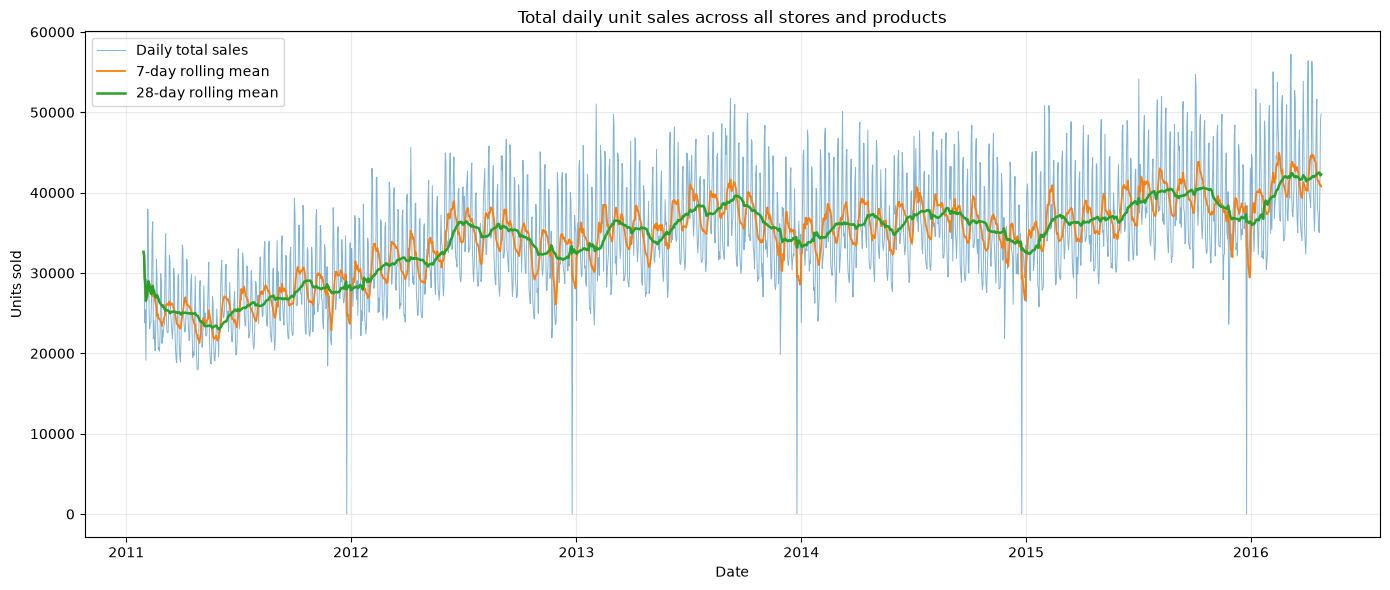

Saved figure: reports/figures/eda_total_daily_sales.png


/home/karanei/SemProject_MLEngine/.venv/lib/python3.12/site-packages/pandas/core/resample.py:2359: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  + Timedelta(days=1, unit=edges_dti.unit).as_unit(edges_dti.unit)


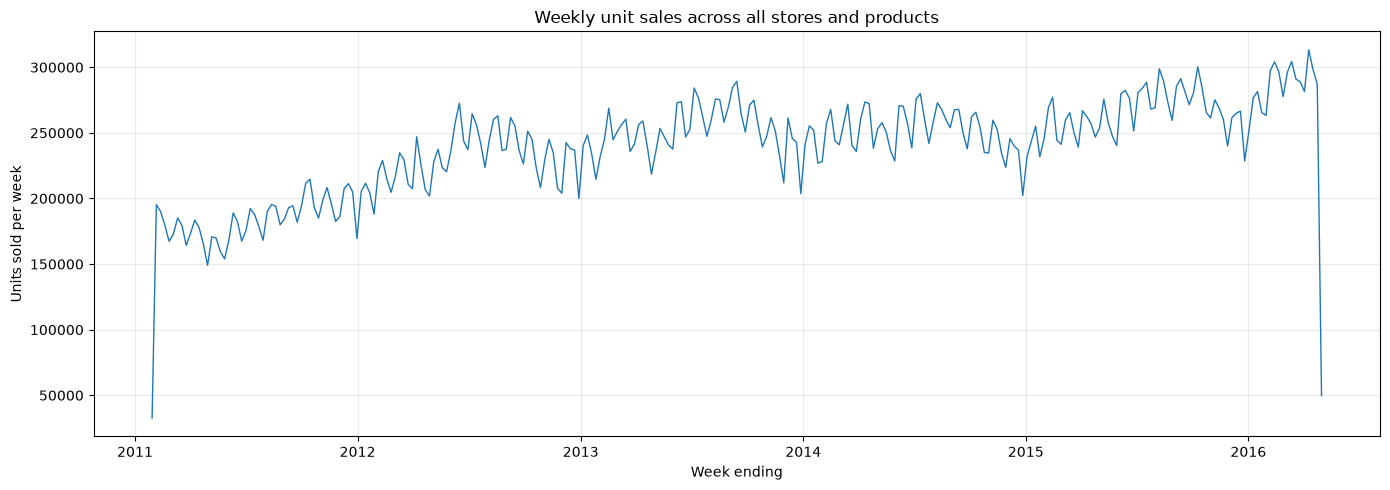

Saved figure: reports/figures/eda_weekly_total_sales.png


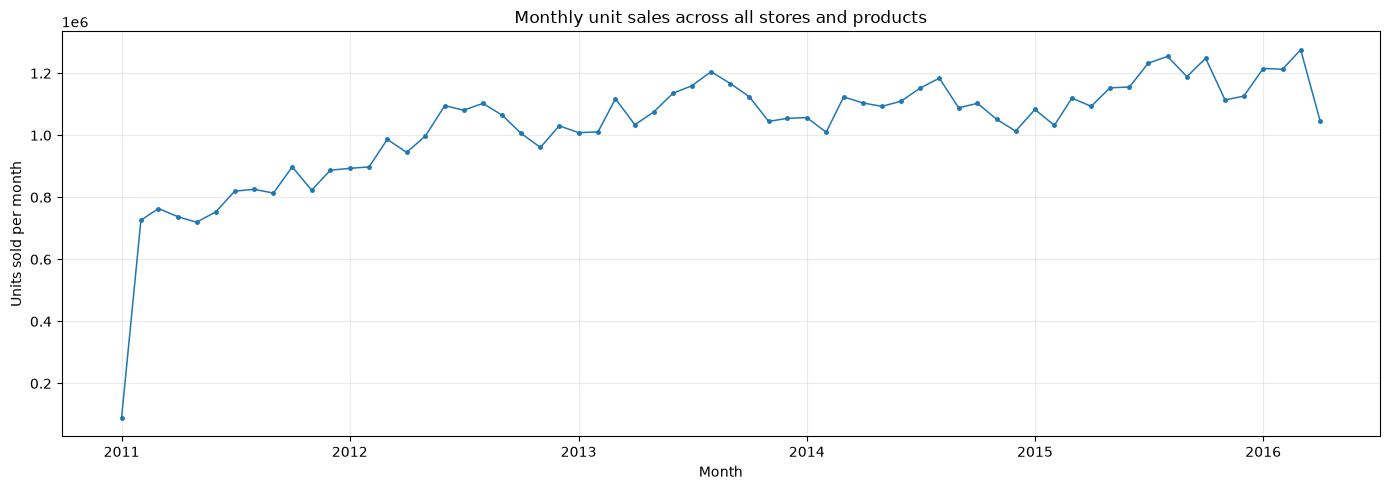

Saved figure: reports/figures/eda_monthly_total_sales.png
Saved table: reports/tables/weekly_total_sales.csv
Saved table: reports/tables/monthly_total_sales.csv


,count,mean,min,25%,50%,75%,max,std
date,1913,2013-09-11 00:00:00,2011-01-29 00:00:00,2012-05-21 00:00:00,2013-09-11 00:00:00,2015-01-02 00:00:00,2016-04-24 00:00:00,NaN
total_units_sold,"1,913.000","34,341.562",11.000,"29,654.000","33,732.000","38,689.000","57,218.000","7,345.905"
rolling_mean_7d,"1,913.000","34,320.693","21,292.143","31,303.429","35,172.429","37,835.429","44,982.286","4,931.618"
rolling_mean_28d,"1,913.000","34,240.783","22,985.714","31,841.429","35,513.679","37,090.857","42,506.643","4,542.052"


In [11]:
# The rolling averages make the longer pattern easier to see through day-to-day noise.
dailySales["rolling_mean_7d"] = dailySales["total_units_sold"].rolling(7, min_periods=1).mean()
dailySales["rolling_mean_28d"] = dailySales["total_units_sold"].rolling(28, min_periods=1).mean()

figure, axis = plt.subplots(figsize=(14, 6))
axis.plot(dailySales["date"], dailySales["total_units_sold"], linewidth=0.7, alpha=0.55, label="Daily total sales")
axis.plot(dailySales["date"], dailySales["rolling_mean_7d"], linewidth=1.3, label="7-day rolling mean")
axis.plot(dailySales["date"], dailySales["rolling_mean_28d"], linewidth=1.8, label="28-day rolling mean")
axis.set_title("Total daily unit sales across all stores and products")
axis.set_xlabel("Date")
axis.set_ylabel("Units sold")
axis.legend()
saveCurrentFigure("eda_total_daily_sales.png")

weeklySales = (
    dailySales.set_index("date")["total_units_sold"]
    .resample("W-SAT").sum().rename("weekly_units_sold").reset_index()
)
monthlySales = (
    dailySales.assign(month_start=dailySales["date"].dt.to_period("M").dt.to_timestamp())
    .groupby("month_start", as_index=False)["total_units_sold"].sum()
    .rename(columns={"total_units_sold": "monthly_units_sold"})
)

figure, axis = plt.subplots(figsize=(14, 5))
axis.plot(weeklySales["date"], weeklySales["weekly_units_sold"], linewidth=1.0)
axis.set_title("Weekly unit sales across all stores and products")
axis.set_xlabel("Week ending")
axis.set_ylabel("Units sold per week")
saveCurrentFigure("eda_weekly_total_sales.png")

figure, axis = plt.subplots(figsize=(14, 5))
axis.plot(monthlySales["month_start"], monthlySales["monthly_units_sold"], marker="o", markersize=2.5, linewidth=1.1)
axis.set_title("Monthly unit sales across all stores and products")
axis.set_xlabel("Month")
axis.set_ylabel("Units sold per month")
saveCurrentFigure("eda_monthly_total_sales.png")

saveTable(weeklySales, "weekly_total_sales.csv")
saveTable(monthlySales, "monthly_total_sales.csv")
display(dailySales[["date", "total_units_sold", "rolling_mean_7d", "rolling_mean_28d"]].describe().T)

##### Which stores and product groups account for sales?

We'll compare sales by state, store, category and department. Since total sales also depend on group size, we'll use per-series summaries where they make comparisons fairer.

,state_id,total_units
0,CA,28675547
1,TX,18899006
2,WI,18120856


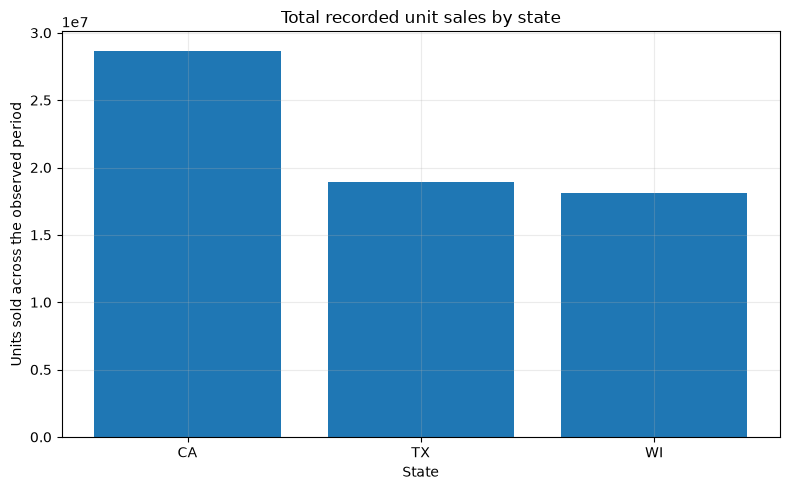

Saved figure: reports/figures/eda_sales_by_state.png
Saved table: reports/tables/sales_by_state.csv


,state_id,store_id,total_units
2,CA,CA_3,11188180
0,CA,CA_1,7698216
5,TX,TX_2,7214384
8,WI,WI_2,6544012
9,WI,WI_3,6427782
6,TX,TX_3,6089330
1,CA,CA_2,5685475
4,TX,TX_1,5595292
7,WI,WI_1,5149062
3,CA,CA_4,4103676


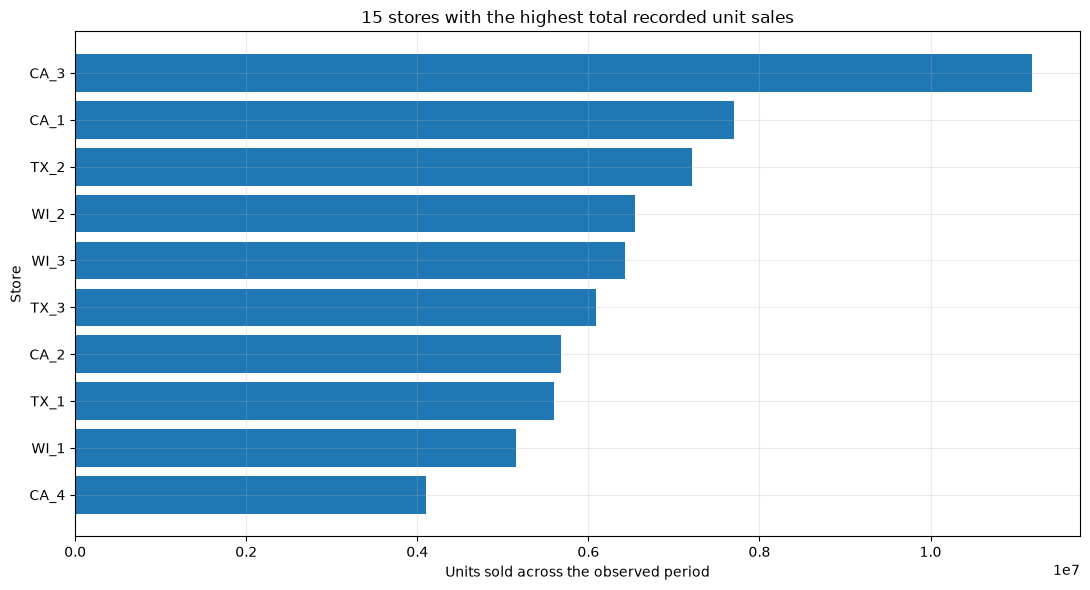

Saved figure: reports/figures/eda_top_stores_by_sales.png
Saved table: reports/tables/sales_by_store.csv


,cat_id,total_units
0,FOODS,45089939
2,HOUSEHOLD,14480670
1,HOBBIES,6124800


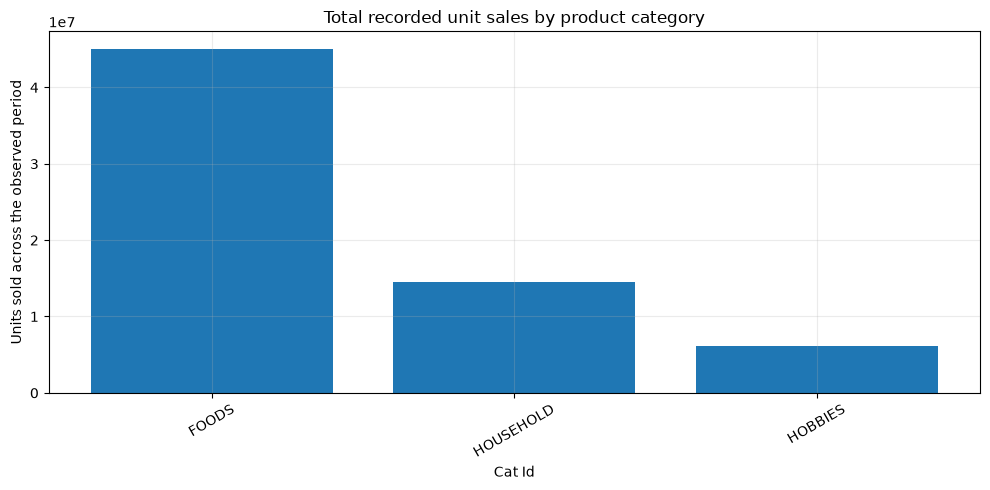

Saved figure: reports/figures/eda_cat_id_sales.png
Saved table: reports/tables/sales_by_category.csv


,dept_id,total_units
2,FOODS_3,32372076
5,HOUSEHOLD_1,11500526
1,FOODS_2,7629822
3,HOBBIES_1,5596460
0,FOODS_1,5088041
6,HOUSEHOLD_2,2980144
4,HOBBIES_2,528340


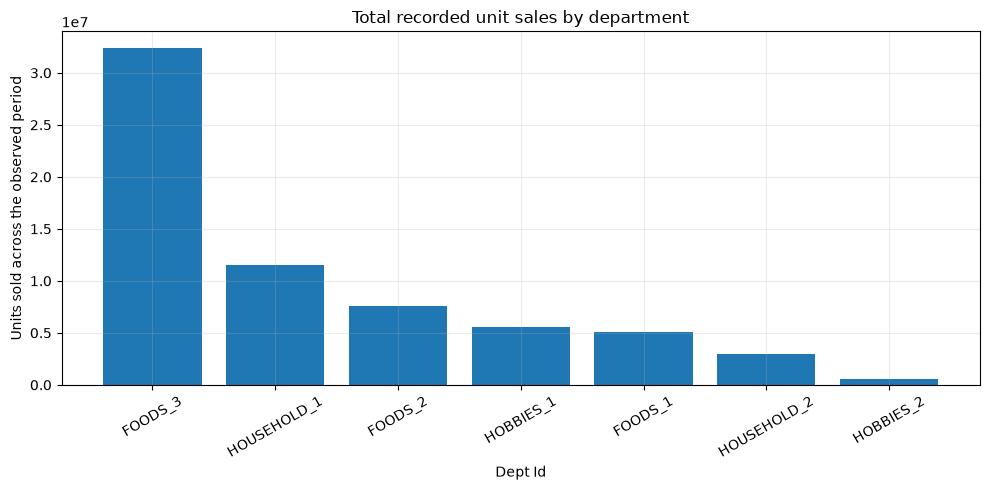

Saved figure: reports/figures/eda_dept_id_sales.png
Saved table: reports/tables/sales_by_department.csv


,cat_id,series_count,median_mean_daily_units,median_total_units,mean_zero_day_share
0,FOODS,14370,0.706,"1,351.000",0.620
1,HOBBIES,5650,0.234,447.500,0.773
2,HOUSEHOLD,10470,0.326,624.000,0.718


Saved table: reports/tables/category_series_summary.csv


In [12]:
# We already calculated totals per product-store series, so use those summaries here.
# Start with the bigger groups, then work down to stores and product groups.
if "state_id" in seriesSummary.columns:
    stateTotals = (
        seriesSummary.groupby("state_id", observed=True, as_index=False)["total_units"]
        .sum().sort_values("total_units", ascending=False)
    )
    display(stateTotals)
    figure, axis = plt.subplots(figsize=(8, 5))
    axis.bar(stateTotals["state_id"].astype(str), stateTotals["total_units"])
    axis.set_title("Total recorded unit sales by state")
    axis.set_xlabel("State")
    axis.set_ylabel("Units sold across the observed period")
    saveCurrentFigure("eda_sales_by_state.png")
    saveTable(stateTotals, "sales_by_state.csv")

if "store_id" in seriesSummary.columns:
    storeTotals = (
        seriesSummary.groupby([columnName for columnName in ["state_id", "store_id"] if columnName in seriesSummary.columns],
                               observed=True, as_index=False)["total_units"]
        .sum().sort_values("total_units", ascending=False)
    )
    topStores = storeTotals.head(15).copy()
    display(topStores)
    figure, axis = plt.subplots(figsize=(11, 6))
    labels = topStores["store_id"].astype(str)
    axis.barh(labels[::-1], topStores["total_units"].to_numpy()[::-1])
    axis.set_title("15 stores with the highest total recorded unit sales")
    axis.set_xlabel("Units sold across the observed period")
    axis.set_ylabel("Store")
    saveCurrentFigure("eda_top_stores_by_sales.png")
    saveTable(storeTotals, "sales_by_store.csv")

for groupColumn, outputName, chartTitle in [
    ("cat_id", "sales_by_category.csv", "Total recorded unit sales by product category"),
    ("dept_id", "sales_by_department.csv", "Total recorded unit sales by department"),
]:
    if groupColumn in seriesSummary.columns:
        groupTotals = (
            seriesSummary.groupby(groupColumn, observed=True, as_index=False)["total_units"]
            .sum().sort_values("total_units", ascending=False)
        )
        display(groupTotals)
        figure, axis = plt.subplots(figsize=(10, 5))
        axis.bar(groupTotals[groupColumn].astype(str), groupTotals["total_units"])
        axis.set_title(chartTitle)
        axis.set_xlabel(groupColumn.replace("_", " ").title())
        axis.set_ylabel("Units sold across the observed period")
        axis.tick_params(axis="x", rotation=30)
        saveCurrentFigure(f"eda_{groupColumn}_sales.png")
        saveTable(groupTotals, outputName)

# Average series-level demand gives us a fairer comparison than category totals alone.
if "cat_id" in seriesSummary.columns:
    categoryStats = (
        seriesSummary.groupby("cat_id", observed=True)
        .agg(
            series_count=("id", "size"),
            median_mean_daily_units=("mean_daily_units", "median"),
            median_total_units=("total_units", "median"),
            mean_zero_day_share=("zero_day_share", "mean"),
        ).reset_index()
    )
    display(categoryStats)
    saveTable(categoryStats, "category_series_summary.csv")

##### How common are zero-sales days?

We'll measure how often each product-store series records zero sales. Frequent zeros can make forecasting harder, but they don't tell us whether an item was unavailable, newly introduced or simply had no sales.

All daily series observations: 58,327,370
Zero-sales observations: 39,777,094 (68.20%)
Series with no recorded sales throughout the history: 0


,condition,series_count,percent_of_series
0,At least 25% of days have zero sales,28930,94.884
1,At least 50% of days have zero sales,23916,78.439
2,At least 75% of days have zero sales,14534,47.668
3,At least 90% of days have zero sales,5284,17.330
4,No recorded sales over the full history,0,0.000


Saved table: reports/tables/demand_sparsity_thresholds.csv


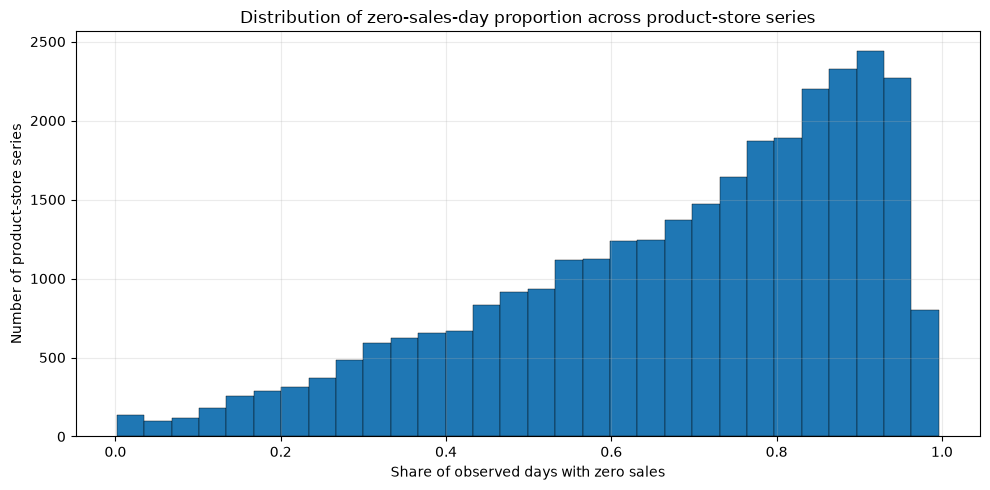

Saved figure: reports/figures/eda_zero_sales_share_distribution.png


,cat_id,series_count,mean_zero_day_share,median_zero_day_share,series_at_least_half_zero,percent_series_at_least_half_zero
0,FOODS,14370,0.620,0.652,10150,70.633
1,HOBBIES,5650,0.773,0.832,5051,89.398
2,HOUSEHOLD,10470,0.718,0.776,8715,83.238


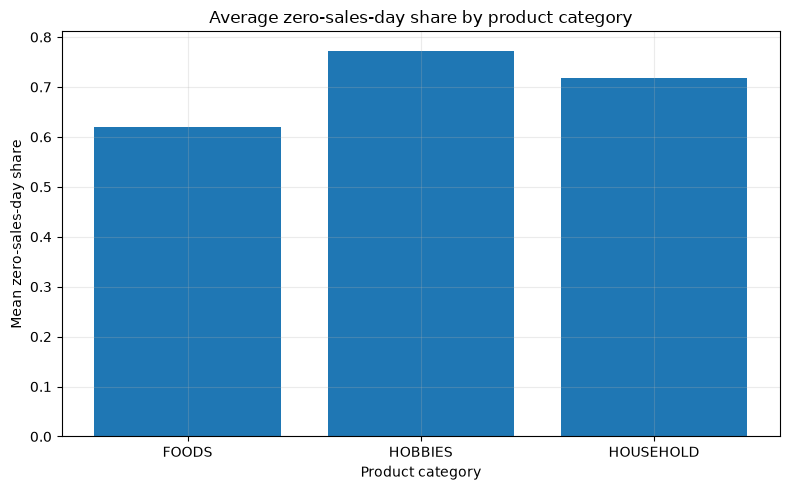

Saved figure: reports/figures/eda_zero_sales_share_by_category.png
Saved table: reports/tables/sparsity_by_category.csv


In [13]:
# Count zeros across every observed product-store day, then look at how zeros vary by series.
zeroObservations = int((salesData[dayColumns] == 0).to_numpy().sum())
totalObservations = int(len(salesData) * len(dayColumns))
zeroShareOverall = zeroObservations / totalObservations if totalObservations else np.nan

print(f"All daily series observations: {totalObservations:,}")
print(f"Zero-sales observations: {zeroObservations:,} ({zeroShareOverall:.2%})")
print(f"Series with no recorded sales throughout the history: {(seriesSummary['total_units'] == 0).sum():,}")

sparsityThresholds = pd.DataFrame({
    "condition": [
        "At least 25% of days have zero sales",
        "At least 50% of days have zero sales",
        "At least 75% of days have zero sales",
        "At least 90% of days have zero sales",
        "No recorded sales over the full history",
    ],
    "series_count": [
        int((seriesSummary["zero_day_share"] >= 0.25).sum()),
        int((seriesSummary["zero_day_share"] >= 0.50).sum()),
        int((seriesSummary["zero_day_share"] >= 0.75).sum()),
        int((seriesSummary["zero_day_share"] >= 0.90).sum()),
        int((seriesSummary["total_units"] == 0).sum()),
    ],
})
sparsityThresholds["percent_of_series"] = 100 * sparsityThresholds["series_count"] / len(seriesSummary)
display(sparsityThresholds)
saveTable(sparsityThresholds, "demand_sparsity_thresholds.csv")

figure, axis = plt.subplots(figsize=(10, 5))
axis.hist(seriesSummary["zero_day_share"].dropna(), bins=30, edgecolor="black", linewidth=0.3)
axis.set_title("Distribution of zero-sales-day proportion across product-store series")
axis.set_xlabel("Share of observed days with zero sales")
axis.set_ylabel("Number of product-store series")
saveCurrentFigure("eda_zero_sales_share_distribution.png")

if "cat_id" in seriesSummary.columns:
    sparsityByCategory = (
        seriesSummary.groupby("cat_id", observed=True)
        .agg(
            series_count=("id", "size"),
            mean_zero_day_share=("zero_day_share", "mean"),
            median_zero_day_share=("zero_day_share", "median"),
            series_at_least_half_zero=("zero_day_share", lambda dailyValues: int((dailyValues >= 0.5).sum())),
        ).reset_index()
    )
    sparsityByCategory["percent_series_at_least_half_zero"] = (
        100 * sparsityByCategory["series_at_least_half_zero"] / sparsityByCategory["series_count"]
    )
    display(sparsityByCategory)
    figure, axis = plt.subplots(figsize=(8, 5))
    axis.bar(sparsityByCategory["cat_id"].astype(str), sparsityByCategory["mean_zero_day_share"])
    axis.set_title("Average zero-sales-day share by product category")
    axis.set_xlabel("Product category")
    axis.set_ylabel("Mean zero-sales-day share")
    saveCurrentFigure("eda_zero_sales_share_by_category.png")
    saveTable(sparsityByCategory, "sparsity_by_category.csv")

##### How variable is demand?

We'll measure variability using the coefficient of variation (CV) across all days and on positive-sales days only. We'll also calculate the average demand interval (ADI), which describes how often sales occur. CV can be unstable when mean demand is very low, so we'll interpret it alongside zero-sales share and ADI.

CV across all days — summary:


,cv_all_days
count,"30,490.000"
mean,2.386
std,1.314
min,0.253
25%,1.459
50%,2.049
75%,2.970
90%,4.095
95%,4.902
99%,6.882


CV of positive-demand days — summary:


,cv_nonzero_demand
count,"30,490.000"
mean,0.592
std,0.197
min,0.000
25%,0.478
50%,0.590
75%,0.680
90%,0.793
95%,0.895
99%,1.162


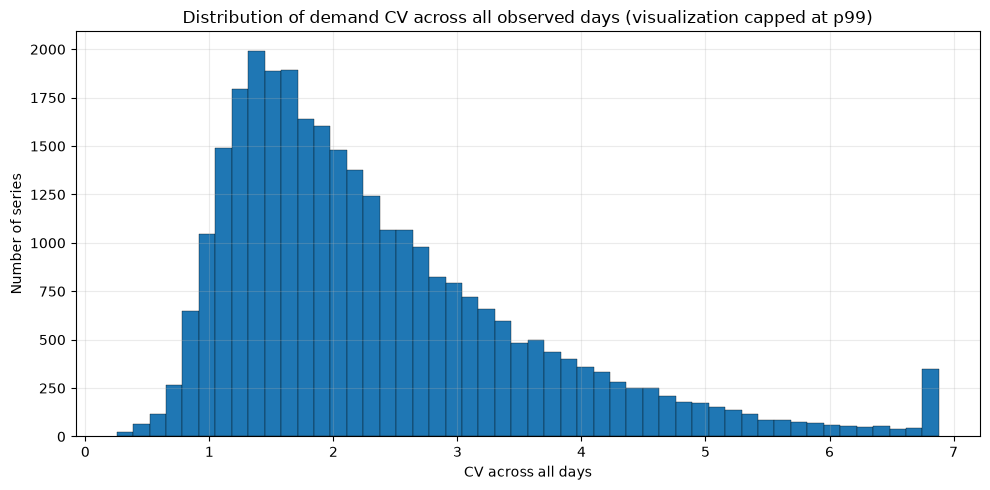

Saved figure: reports/figures/eda_cv_all_days_distribution.png


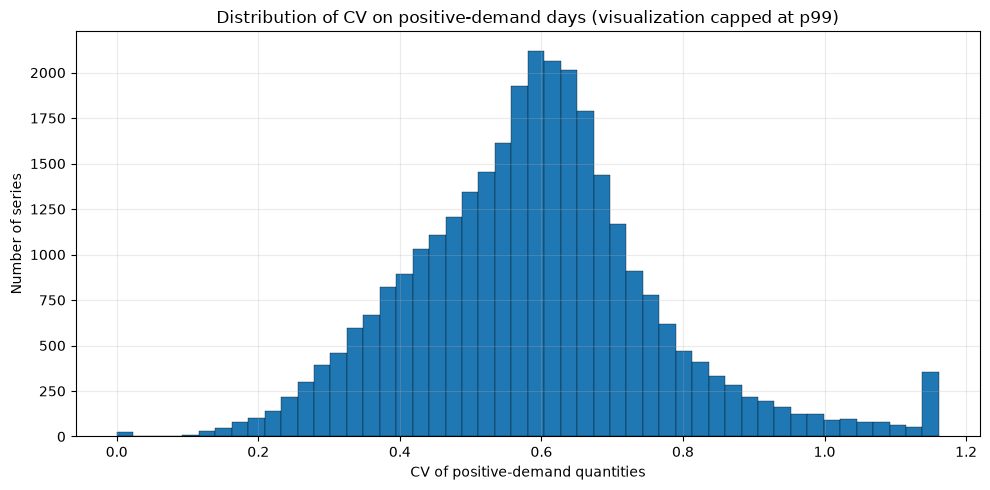

Saved figure: reports/figures/eda_cv_positive_days_distribution.png


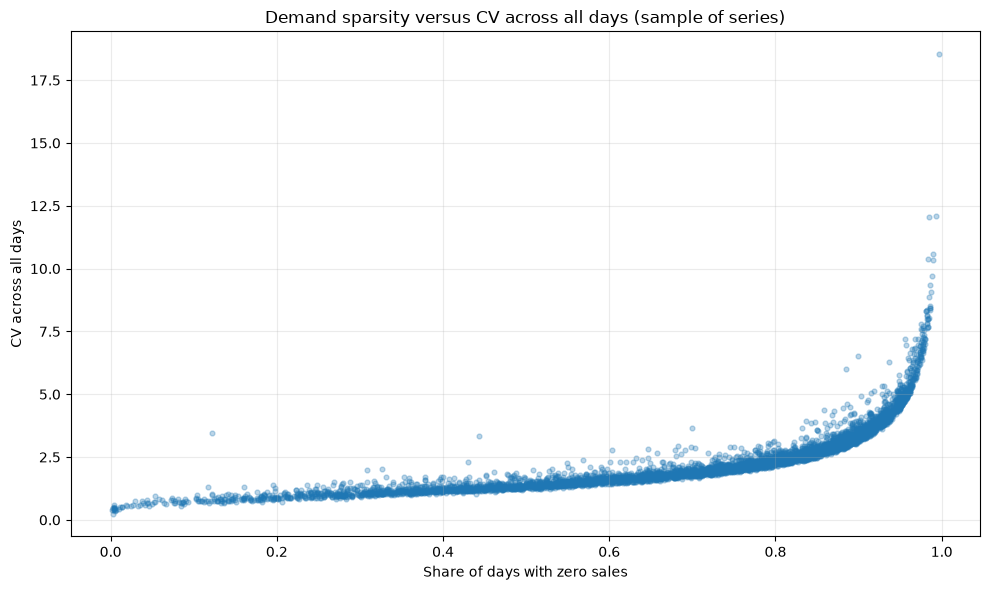

Saved figure: reports/figures/eda_sparsity_vs_volatility.png


,cat_id,series_count,median_cv_all_days,median_cv_nonzero,median_adi,median_zero_day_share
0,FOODS,14370,1.792,0.644,2.877,0.652
1,HOBBIES,5650,2.621,0.506,5.969,0.832
2,HOUSEHOLD,10470,2.165,0.530,4.459,0.776


Saved table: reports/tables/volatility_by_category.csv
Volatility terciles are exploratory only; determine thresholds from training data for formal evaluation.


In [14]:
volatilitySummary = seriesSummary[
    ["id", "cat_id", "dept_id", "store_id", "total_units", "mean_daily_units",
     "std_daily_units", "zero_day_share", "average_demand_interval",
     "cv_all_days", "cv_nonzero_demand"]
].copy()

# Keep infinite CV values out of the summaries; they can occur when average demand is zero.
validCvAll = volatilitySummary["cv_all_days"].replace([np.inf, -np.inf], np.nan).dropna()
validCvPositive = volatilitySummary["cv_nonzero_demand"].replace([np.inf, -np.inf], np.nan).dropna()

print("CV across all days — summary:")
display(validCvAll.describe(percentiles=[0.25, 0.5, 0.75, 0.90, 0.95, 0.99]).to_frame("cv_all_days"))
print("CV of positive-demand days — summary:")
display(validCvPositive.describe(percentiles=[0.25, 0.5, 0.75, 0.90, 0.95, 0.99]).to_frame("cv_nonzero_demand"))

# A few extreme values can flatten the chart, so cap the displayed tail for readability only.
if not validCvAll.empty:
    upperCv = validCvAll.quantile(0.99)
    figure, axis = plt.subplots(figsize=(10, 5))
    axis.hist(validCvAll.clip(upper=upperCv), bins=50, edgecolor="black", linewidth=0.25)
    axis.set_title("Distribution of demand CV across all observed days (visualization capped at p99)")
    axis.set_xlabel("CV across all days")
    axis.set_ylabel("Number of series")
    saveCurrentFigure("eda_cv_all_days_distribution.png")

if not validCvPositive.empty:
    upperCvPositive = validCvPositive.quantile(0.99)
    figure, axis = plt.subplots(figsize=(10, 5))
    axis.hist(validCvPositive.clip(upper=upperCvPositive), bins=50, edgecolor="black", linewidth=0.25)
    axis.set_title("Distribution of CV on positive-demand days (visualization capped at p99)")
    axis.set_xlabel("CV of positive-demand quantities")
    axis.set_ylabel("Number of series")
    saveCurrentFigure("eda_cv_positive_days_distribution.png")

# Use a sample for this plot; we do not need every series to see the broad pattern.
scatterData = volatilitySummary.dropna(subset=["zero_day_share", "cv_all_days"]).sample(
    n=min(5000, volatilitySummary.dropna(subset=["zero_day_share", "cv_all_days"]).shape[0]),
    random_state=randomSeed,
)
figure, axis = plt.subplots(figsize=(10, 6))
axis.scatter(scatterData["zero_day_share"], scatterData["cv_all_days"], alpha=0.3, s=12)
axis.set_title("Demand sparsity versus CV across all days (sample of series)")
axis.set_xlabel("Share of days with zero sales")
axis.set_ylabel("CV across all days")
saveCurrentFigure("eda_sparsity_vs_volatility.png")

if "cat_id" in volatilitySummary.columns:
    volatilityByCategory = (
        volatilitySummary.groupby("cat_id", observed=True)
        .agg(
            series_count=("id", "size"),
            median_cv_all_days=("cv_all_days", "median"),
            median_cv_nonzero=("cv_nonzero_demand", "median"),
            median_adi=("average_demand_interval", "median"),
            median_zero_day_share=("zero_day_share", "median"),
        ).reset_index()
    )
    display(volatilityByCategory)
    saveTable(volatilityByCategory, "volatility_by_category.csv")

# These low/medium/high groups are only for exploring the data. They are relative to this dataset,
# so we will set any formal modelling thresholds using training data only.
cvValidMask = seriesSummary["cv_all_days"].notna()
seriesSummary["volatility_tercile_eda"] = pd.NA
if cvValidMask.sum() >= 3:
    ranks = seriesSummary.loc[cvValidMask, "cv_all_days"].rank(method="first", pct=True)
    seriesSummary.loc[cvValidMask, "volatility_tercile_eda"] = pd.cut(
        ranks,
        bins=[0, 1/3, 2/3, 1.0000001],
        labels=["Low", "Medium", "High"],
        include_lowest=True,
    ).astype(str)
print("Volatility terciles are exploratory only; determine thresholds from training data for formal evaluation.")

##### Do sales follow calendar patterns?

We'll compare sales by weekday, month and year. These patterns may help us decide whether calendar features or a weekly seasonal baseline are useful. We'll be careful with year-on-year comparisons when the first or last year is incomplete.

,weekday,mean_daily_units,index_vs_overall_mean
0,Saturday,"41,546.894",120.981
1,Sunday,"41,130.022",119.767
2,Monday,"32,852.967",95.665
3,Tuesday,"30,368.780",88.432
4,Wednesday,"30,010.022",87.387
5,Thursday,"30,205.007",87.955
6,Friday,"34,225.985",99.663


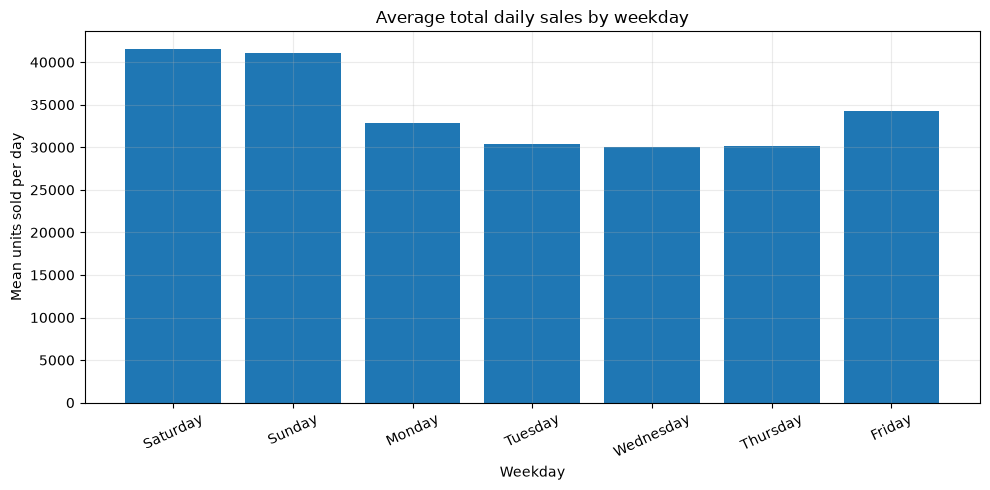

Saved figure: reports/figures/eda_average_sales_by_weekday.png
Saved table: reports/tables/sales_by_weekday.csv


,month_num,mean_daily_units,month_name
0,1,"33,832.348",Jan
1,2,"34,644.641",Feb
2,3,"34,339.839",Mar
3,4,"34,258.684",Apr
4,5,"32,503.852",May
5,6,"35,001.413",Jun
6,7,"35,122.419",Jul
7,8,"35,946.645",Aug
8,9,"35,479.260",Sep
9,10,"34,713.477",Oct


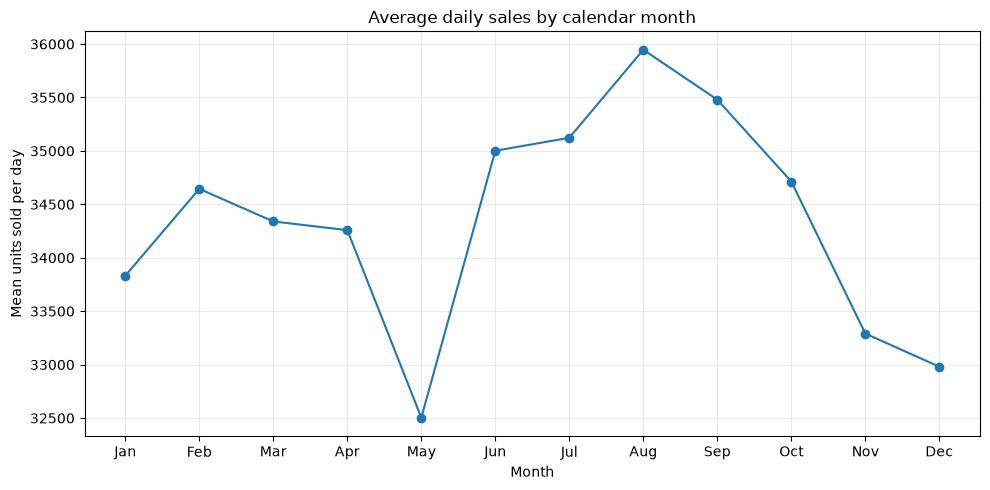

Saved figure: reports/figures/eda_average_sales_by_month_of_year.png
Saved table: reports/tables/sales_by_month_of_year.csv


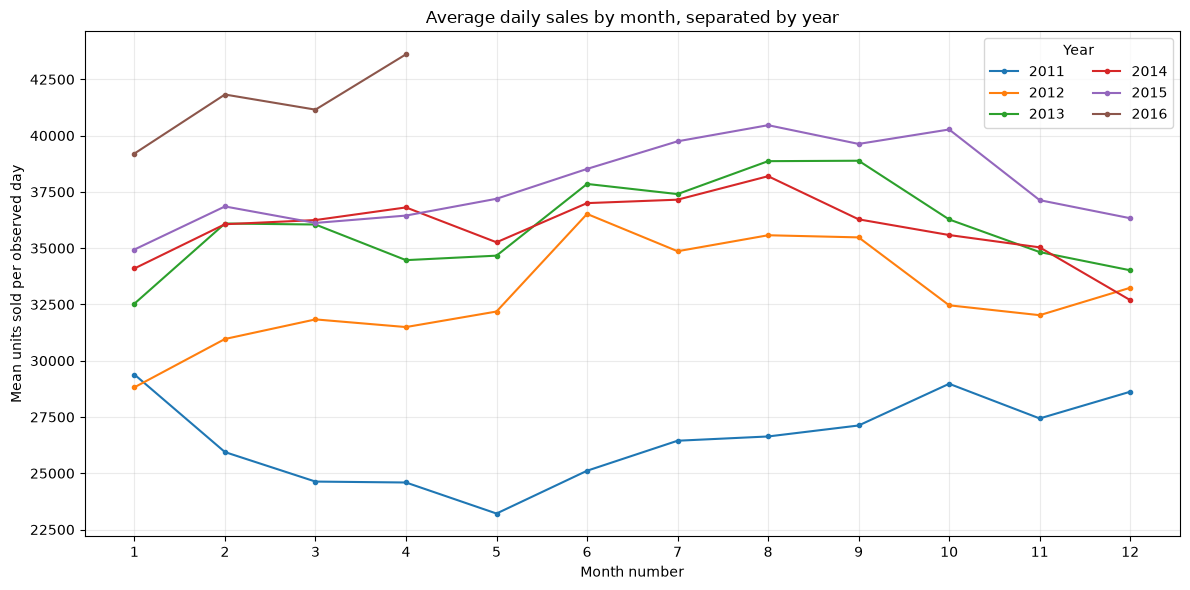

Saved figure: reports/figures/eda_monthly_pattern_by_year.png
Saved table: reports/tables/monthly_sales_by_year.csv


In [15]:
# Keep weekdays in calendar order instead of sorting them alphabetically.
weekdayOrder = ["Saturday", "Sunday", "Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
weekdayMeans = (
    dailySales.groupby("weekday", observed=True)["total_units_sold"].mean()
    .reindex(weekdayOrder).dropna().rename("mean_daily_units").reset_index()
)
weekdayMeans["index_vs_overall_mean"] = (
    100 * weekdayMeans["mean_daily_units"] / dailySales["total_units_sold"].mean()
)

display(weekdayMeans)
figure, axis = plt.subplots(figsize=(10, 5))
axis.bar(weekdayMeans["weekday"].astype(str), weekdayMeans["mean_daily_units"])
axis.set_title("Average total daily sales by weekday")
axis.set_xlabel("Weekday")
axis.set_ylabel("Mean units sold per day")
axis.tick_params(axis="x", rotation=25)
saveCurrentFigure("eda_average_sales_by_weekday.png")
saveTable(weekdayMeans, "sales_by_weekday.csv")

monthOrder = list(range(1, 13))
monthlySeasonality = (
    dailySales.groupby("month_num", observed=True)["total_units_sold"].mean()
    .reindex(monthOrder).rename("mean_daily_units").reset_index()
)
monthlySeasonality["month_name"] = monthlySeasonality["month_num"].map(lambda monthNumber: pd.Timestamp(2000, int(monthNumber), 1).strftime("%b"))
display(monthlySeasonality)
figure, axis = plt.subplots(figsize=(10, 5))
axis.plot(monthlySeasonality["month_name"], monthlySeasonality["mean_daily_units"], marker="o")
axis.set_title("Average daily sales by calendar month")
axis.set_xlabel("Month")
axis.set_ylabel("Mean units sold per day")
saveCurrentFigure("eda_average_sales_by_month_of_year.png")
saveTable(monthlySeasonality, "sales_by_month_of_year.csv")

# Looking at each year separately helps us see whether the month pattern repeats.
monthlyByYear = (
    dailySales.assign(month_start=dailySales["date"].dt.to_period("M").dt.to_timestamp())
    .groupby(["year_num", "month_num"], observed=True)
    .agg(monthly_units=("total_units_sold", "sum"), days_observed=("date", "count"))
    .reset_index()
)
monthlyByYear["mean_daily_units"] = monthlyByYear["monthly_units"] / monthlyByYear["days_observed"]
figure, axis = plt.subplots(figsize=(12, 6))
for calendarYear, seriesGroup in monthlyByYear.groupby("year_num", observed=True):
    axis.plot(seriesGroup["month_num"], seriesGroup["mean_daily_units"], marker="o", markersize=3, label=str(calendarYear))
axis.set_title("Average daily sales by month, separated by year")
axis.set_xlabel("Month number")
axis.set_ylabel("Mean units sold per observed day")
axis.set_xticks(monthOrder)
axis.legend(title="Year", ncol=2)
saveCurrentFigure("eda_monthly_pattern_by_year.png")
saveTable(monthlyByYear, "monthly_sales_by_year.csv")

##### Events and holidays

We'll compare sales on dates with recorded events against other dates and summarize event names that occur often enough. This is descriptive only: weekday, season and trend may also explain differences. Blank event names are normal for many calendar dates.

,has_recorded_event,number_of_days,mean_daily_units,median_daily_units,std_daily_units,day_type
0,False,1759,"34,489.208","33,714.000","7,133.702",No recorded event
1,True,154,"32,655.149","33,779.500","9,300.906",Recorded event


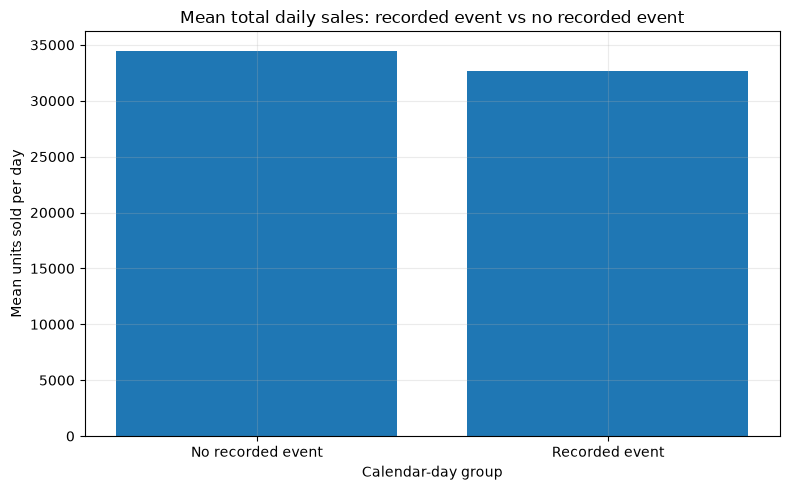

Saved figure: reports/figures/eda_event_vs_non_event_sales.png
Saved table: reports/tables/event_day_comparison.csv


,event_source_column,event_name,number_of_occurrences,mean_daily_units
11,event_name_1,LentStart,6,"30,727.000"
12,event_name_1,LentWeek2,6,"29,747.000"
26,event_name_1,SuperBowl,6,"40,924.000"
22,event_name_1,PresidentsDay,6,"34,446.333"
25,event_name_1,StPatricksDay,6,"33,459.667"
28,event_name_1,ValentinesDay,6,"33,495.667"
23,event_name_1,Purim End,6,"35,957.000"
0,event_name_1,Chanukah End,5,"33,426.800"
1,event_name_1,Christmas,5,15.600
3,event_name_1,ColumbusDay,5,"35,164.800"


Saved table: reports/tables/sales_by_event_name.csv


,event_source_column,event_type,number_of_occurrences,mean_daily_units
2,event_type_1,Religious,52,"33,760.692"
1,event_type_1,National,51,"29,458.510"
0,event_type_1,Cultural,35,"34,234.743"
3,event_type_1,Sporting,16,"35,796.062"
4,event_type_2,Cultural,3,"36,571.667"
5,event_type_2,Religious,1,"38,934.000"


Saved table: reports/tables/sales_by_event_type.csv


In [16]:
# First compare days with any recorded event, then inspect individual event names/types.
eventColumns = [columnName for columnName in ["event_name_1", "event_name_2"] if columnName in dailySales.columns]
if eventColumns:
    dailySales["has_recorded_event"] = dailySales[eventColumns].notna().any(axis=1)
    eventComparison = (
        dailySales.groupby("has_recorded_event", observed=True)
        .agg(
            number_of_days=("date", "count"),
            mean_daily_units=("total_units_sold", "mean"),
            median_daily_units=("total_units_sold", "median"),
            std_daily_units=("total_units_sold", "std"),
        ).reset_index()
    )
    eventComparison["day_type"] = eventComparison["has_recorded_event"].map({True: "Recorded event", False: "No recorded event"})
    display(eventComparison)

    figure, axis = plt.subplots(figsize=(8, 5))
    axis.bar(eventComparison["day_type"], eventComparison["mean_daily_units"])
    axis.set_title("Mean total daily sales: recorded event vs no recorded event")
    axis.set_xlabel("Calendar-day group")
    axis.set_ylabel("Mean units sold per day")
    saveCurrentFigure("eda_event_vs_non_event_sales.png")
    saveTable(eventComparison, "event_day_comparison.csv")

    eventNameFrames = []
    for eventColumn in eventColumns:
        eventRows = dailySales.loc[dailySales[eventColumn].notna(), ["date", "total_units_sold", eventColumn]].copy()
        eventRows = eventRows.rename(columns={eventColumn: "event_name"})
        eventRows["event_source_column"] = eventColumn
        eventNameFrames.append(eventRows)
    eventRecords = pd.concat(eventNameFrames, ignore_index=True) if eventNameFrames else pd.DataFrame()
    if not eventRecords.empty:
        eventNameSummary = (
            eventRecords.groupby(["event_source_column", "event_name"], observed=True)
            .agg(number_of_occurrences=("date", "count"), mean_daily_units=("total_units_sold", "mean"))
            .reset_index()
            .sort_values("number_of_occurrences", ascending=False)
        )
        display(eventNameSummary.head(20))
        saveTable(eventNameSummary, "sales_by_event_name.csv")
else:
    print("No event-name columns were found in the loaded calendar data; skipping event analysis.")

# If event types are available, see which ones show up often and how sales look on those days.
eventTypeColumns = [columnName for columnName in ["event_type_1", "event_type_2"] if columnName in dailySales.columns]
if eventTypeColumns:
    eventTypeRecords = []
    for eventColumn in eventTypeColumns:
        eventRows = dailySales.loc[dailySales[eventColumn].notna(), ["date", "total_units_sold", eventColumn]].copy()
        eventRows = eventRows.rename(columns={eventColumn: "event_type"})
        eventRows["event_source_column"] = eventColumn
        eventTypeRecords.append(eventRows)
    eventTypeFrame = pd.concat(eventTypeRecords, ignore_index=True)
    eventTypeSummary = (
        eventTypeFrame.groupby(["event_source_column", "event_type"], observed=True)
        .agg(number_of_occurrences=("date", "count"), mean_daily_units=("total_units_sold", "mean"))
        .reset_index().sort_values("number_of_occurrences", ascending=False)
    )
    display(eventTypeSummary)
    saveTable(eventTypeSummary, "sales_by_event_type.csv")

##### SNAP(food stamp) indicators by state

The calendar includes SNAP indicators for California (`snap_CA`), Texas (`snap_TX`) and Wisconsin (`snap_WI`). We'll compare state-level sales on active and inactive days. Any difference is an association, not proof that SNAP caused a change in sales.

,state_id,snap_active,number_of_days,mean_daily_units,median_daily_units,day_group
0,CA,False,1283,"14,605.814","14,340.000",SNAP indicator inactive
1,CA,True,630,"15,771.886","15,385.000",SNAP indicator active
2,TX,False,1283,"9,519.083","9,298.000",SNAP indicator inactive
3,TX,True,630,"10,612.735","10,405.500",SNAP indicator active
4,WI,False,1283,"8,838.505","8,696.000",SNAP indicator inactive
5,WI,True,630,"10,763.578","10,831.500",SNAP indicator active


Saved table: reports/tables/snap_sales_comparison_by_state.csv


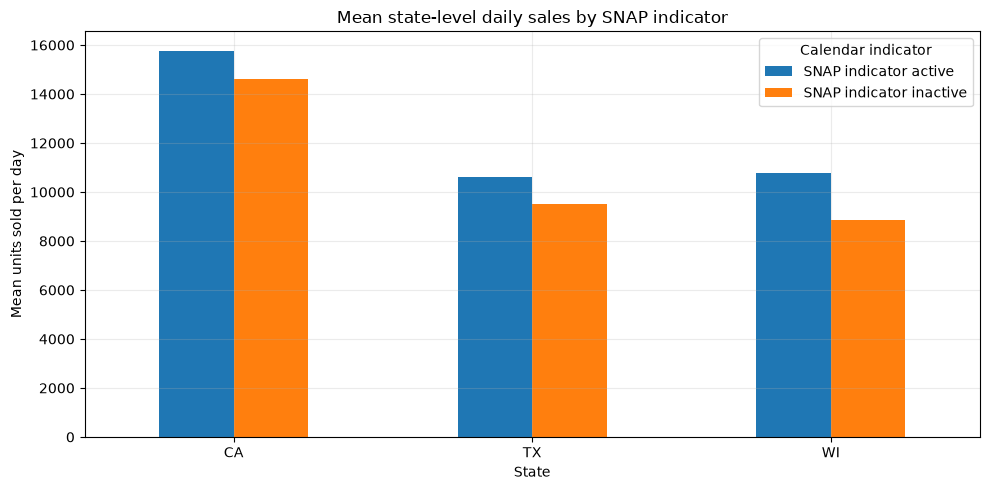

Saved figure: reports/figures/eda_snap_indicator_by_state.png


In [18]:
# SNAP is state-specific in this dataset, so compare each state with its own indicator.
snapColumnsByState = {"CA": "snap_CA", "TX": "snap_TX", "WI": "snap_WI"}
snapResultRows = []
stateDailyFrames = []

if "state_id" in salesData.columns:
    for stateCode, snapColumn in snapColumnsByState.items():
        if snapColumn not in calendarForEda.columns:
            continue
        stateMask = salesData["state_id"].astype(str).eq(stateCode)
        if not stateMask.any():
            continue
        stateSalesByDay = salesData.loc[stateMask, dayColumns].sum(axis=0).to_numpy(dtype=np.int64)
        stateDaily = pd.DataFrame({
            "d": dayColumns,
            "state_id": stateCode,
            "total_units_sold": stateSalesByDay,
        }).merge(
            calendarForEda[["d", "date", snapColumn]],
            on="d", how="left", validate="one_to_one"
        )
        stateDaily["snap_active"] = stateDaily[snapColumn].fillna(0).astype(int).eq(1)
        comparison = (
            stateDaily.groupby("snap_active", observed=True)
            .agg(
                number_of_days=("date", "count"),
                mean_daily_units=("total_units_sold", "mean"),
                median_daily_units=("total_units_sold", "median"),
            ).reset_index()
        )
        for _, comparisonRow in comparison.iterrows():
            snapResultRows.append({
                "state_id": stateCode,
                "snap_active": bool(comparisonRow["snap_active"]),
                "number_of_days": int(comparisonRow["number_of_days"]),
                "mean_daily_units": float(comparisonRow["mean_daily_units"]),
                "median_daily_units": float(comparisonRow["median_daily_units"]),
            })
        stateDailyFrames.append(stateDaily[["date", "state_id", "total_units_sold", "snap_active"]])

snapComparison = pd.DataFrame(snapResultRows)
if not snapComparison.empty:
    snapComparison["day_group"] = snapComparison["snap_active"].map({True: "SNAP indicator active", False: "SNAP indicator inactive"})
    display(snapComparison)
    saveTable(snapComparison, "snap_sales_comparison_by_state.csv")

    figure, axis = plt.subplots(figsize=(10, 5))
    pivotSnap = snapComparison.pivot(index="state_id", columns="day_group", values="mean_daily_units")
    pivotSnap.plot(kind="bar", ax=axis)
    axis.set_title("Mean state-level daily sales by SNAP indicator")
    axis.set_xlabel("State")
    axis.set_ylabel("Mean units sold per day")
    axis.tick_params(axis="x", rotation=0)
    axis.legend(title="Calendar indicator")
    saveCurrentFigure("eda_snap_indicator_by_state.png")
else:
    print("SNAP comparison skipped: expected state IDs or SNAP columns were not available.")

##### What do prices look like, and how do they line up with sales?

Prices are recorded weekly by item and store, while sales are daily. We'll inspect price variation, then aggregate a manageable sample of daily sales to the week and match it to the relevant price records. Price and sales moving together doesn't prove causation; when forecasting, we'll also need to use only prices that would have been known at prediction time.

,sell_price
count,"6,841,121.000"
mean,4.411
std,3.409
min,0.010
1%,0.480
10%,1.240
25%,2.180
50%,3.470
75%,5.840
90%,8.640


Saved table: reports/tables/sell_price_descriptive_statistics.csv


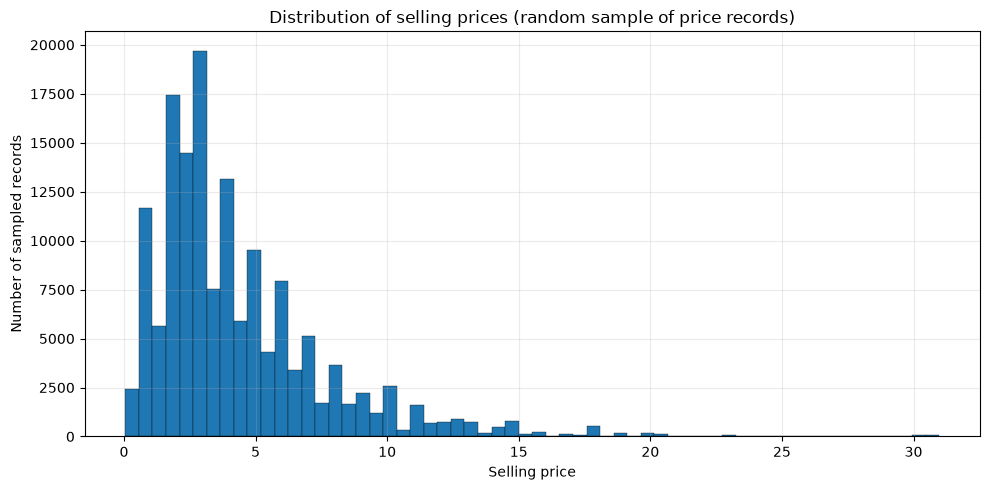

Saved figure: reports/figures/eda_sell_price_distribution.png


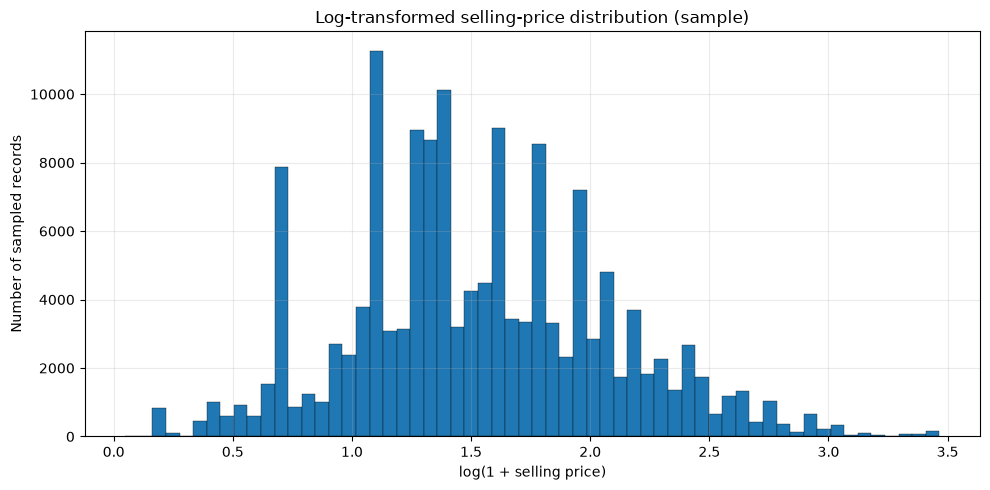

Saved figure: reports/figures/eda_sell_price_log_distribution.png


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
store_id,30490,10,CA_1,3049,NaN,NaN,NaN,NaN,NaN,NaN,NaN
item_id,30490,3049,FOODS_1_001,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
number_of_price_weeks,"30,490.000",NaN,NaN,NaN,224.373,68.001,19.000,173.000,260.000,282.000,282.000
minimum_price,"30,490.000",NaN,NaN,NaN,4.017,3.342,0.010,1.970,2.970,4.980,29.970
maximum_price,"30,490.000",NaN,NaN,NaN,4.630,3.717,0.230,2.280,3.540,5.960,107.320
mean_price,"30,490.000",NaN,NaN,NaN,4.452,3.520,0.192,2.172,3.377,5.807,30.506
std_price,"30,490.000",NaN,NaN,NaN,0.137,0.224,0.000,0.000,0.079,0.190,12.584
relative_price_range,"30,490.000",NaN,NaN,NaN,0.144,0.199,0.000,0.000,0.088,0.193,7.934


Saved table: reports/tables/price_variation_by_item_store.csv
Sampled product-store series: 60
Weekly sales observations with a matching price: 83.24%
Saved table: reports/tables/sampled_weekly_sales_and_prices.csv


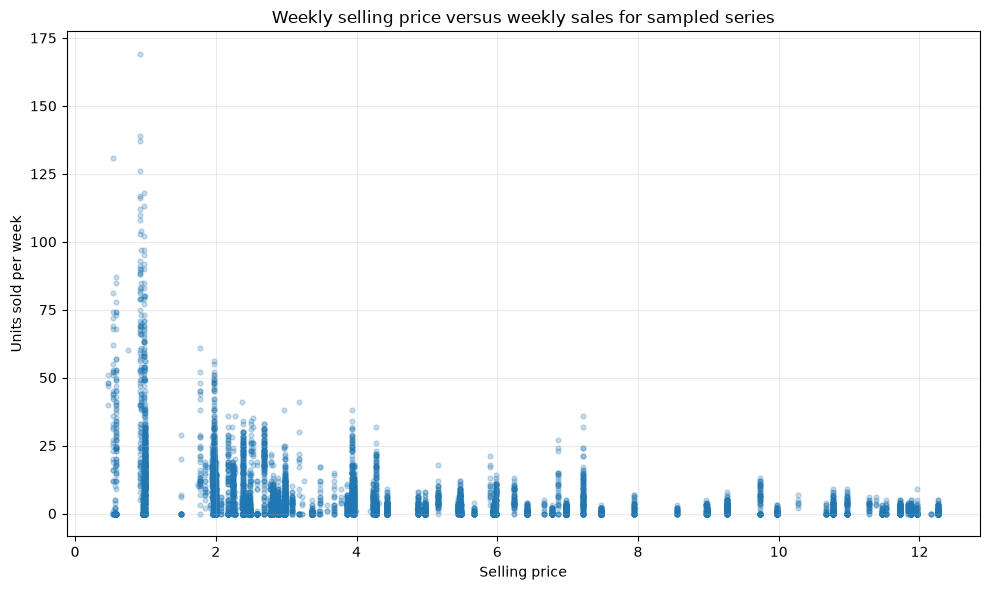

Saved figure: reports/figures/eda_weekly_price_vs_sales_sample.png


,within_series_price_sales_correlation
count,45.000
mean,-0.043
std,0.254
min,-0.519
25%,-0.192
50%,-0.012
75%,0.110
max,0.806


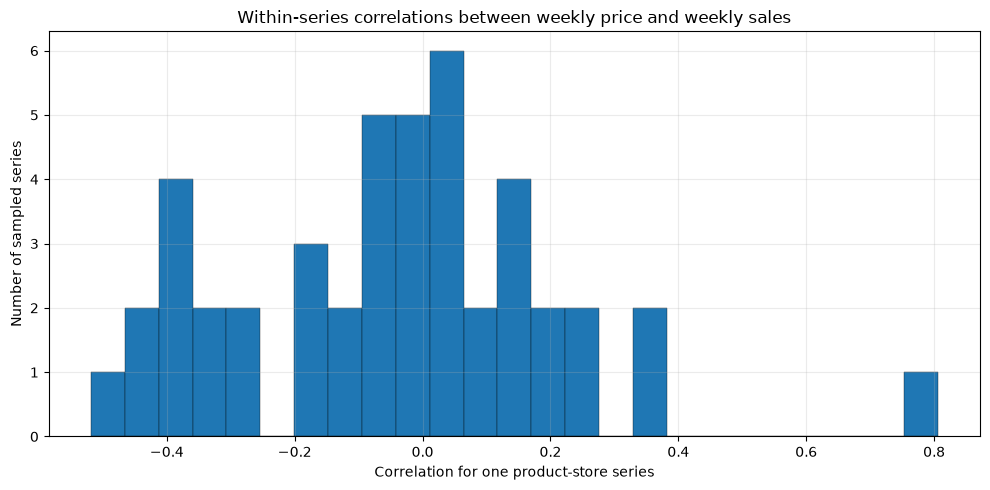

Saved figure: reports/figures/eda_within_series_price_sales_correlations.png
Saved table: reports/tables/sampled_price_sales_correlations.csv


In [17]:
if "sell_price" in priceData.columns:
    priceDescription = priceData["sell_price"].describe(percentiles=[0.01, 0.10, 0.25, 0.50, 0.75, 0.90, 0.99]).to_frame("sell_price")
    display(priceDescription)
    saveTable(priceDescription, "sell_price_descriptive_statistics.csv")

    priceSample = priceData["sell_price"].dropna().sample(
        n=min(150_000, int(priceData["sell_price"].notna().sum())),
        random_state=randomSeed,
    )
    figure, axis = plt.subplots(figsize=(10, 5))
    axis.hist(priceSample, bins=60, edgecolor="black", linewidth=0.25)
    axis.set_title("Distribution of selling prices (random sample of price records)")
    axis.set_xlabel("Selling price")
    axis.set_ylabel("Number of sampled records")
    saveCurrentFigure("eda_sell_price_distribution.png")

    figure, axis = plt.subplots(figsize=(10, 5))
    positivePrices = priceSample[priceSample > 0]
    if not positivePrices.empty:
        axis.hist(np.log1p(positivePrices), bins=60, edgecolor="black", linewidth=0.25)
        axis.set_title("Log-transformed selling-price distribution (sample)")
        axis.set_xlabel("log(1 + selling price)")
        axis.set_ylabel("Number of sampled records")
        saveCurrentFigure("eda_sell_price_log_distribution.png")

    # Compare each product-store price range with its average price.
    priceVariation = (
        priceData.groupby(["store_id", "item_id"], observed=True)["sell_price"]
        .agg(number_of_price_weeks="count", minimum_price="min", maximum_price="max", mean_price="mean", std_price="std")
        .reset_index()
    )
    priceVariation["relative_price_range"] = np.divide(
        priceVariation["maximum_price"] - priceVariation["minimum_price"],
        priceVariation["mean_price"],
        out=np.full(len(priceVariation), np.nan, dtype=np.float64),
        where=priceVariation["mean_price"].to_numpy(dtype=np.float64) > 0,
    )
    display(priceVariation.describe(include="all").T)
    saveTable(priceVariation, "price_variation_by_item_store.csv")

    # Sample a few series across categories and add their daily sales up to the weekly price level.
    sampleParts = []
    if "cat_id" in salesData.columns:
        for _, categoryFrame in salesData.groupby("cat_id", observed=True, sort=False):
            sampleParts.append(categoryFrame.sample(
                n=min(20, len(categoryFrame)), random_state=randomSeed
            ))
    else:
        sampleParts = [salesData.sample(n=min(60, len(salesData)), random_state=randomSeed)]

    sampledSales = pd.concat(sampleParts, ignore_index=True).drop_duplicates(subset=["id"])
    sampleIdColumns = [columnName for columnName in ["id", "item_id", "store_id", "cat_id"] if columnName in sampledSales.columns]
    # Only reshape the sampled product-store series; melting the full table would be much heavier.
    sampledLong = sampledSales[sampleIdColumns + dayColumns].melt(
        id_vars=sampleIdColumns,
        value_vars=dayColumns,
        var_name="d",
        value_name="daily_units_sold",
    )
    for keyColumn in ["item_id", "store_id"]:
        sampledLong[keyColumn] = sampledLong[keyColumn].astype(str)
    calendarPriceKeys = calendarForEda[["d", "date", "wm_yr_wk"]].copy()
    calendarPriceKeys["d"] = calendarPriceKeys["d"].astype(str)
    sampledLong = sampledLong.merge(
        calendarPriceKeys, on="d", how="left", validate="many_to_one"
    )
    weeklySampleSales = (
        sampledLong.groupby(sampleIdColumns + ["wm_yr_wk"], observed=True, as_index=False)["daily_units_sold"]
        .sum().rename(columns={"daily_units_sold": "weekly_units_sold"})
    )
    pricesForMerge = priceData[["store_id", "item_id", "wm_yr_wk", "sell_price"]].copy()
    for keyColumn in ["item_id", "store_id"]:
        pricesForMerge[keyColumn] = pricesForMerge[keyColumn].astype(str)
    # Match sales aggregated to weeks with the price recorded for that same store, item and week.
    weeklyPriceDemand = weeklySampleSales.merge(
        pricesForMerge,
        on=["store_id", "item_id", "wm_yr_wk"],
        how="left",
        validate="many_to_one",
    )

    samplePriceCoverage = float(weeklyPriceDemand["sell_price"].notna().mean()) if len(weeklyPriceDemand) else np.nan
    print(f"Sampled product-store series: {sampledSales['id'].nunique():,}")
    print(f"Weekly sales observations with a matching price: {samplePriceCoverage:.2%}")
    saveTable(weeklyPriceDemand, "sampled_weekly_sales_and_prices.csv")

    # This scatter mixes products, so treat it as an overview. The correlations below are within each series.
    matchedPriceSales = weeklyPriceDemand.dropna(subset=["sell_price"]).sample(
        n=min(8000, int(weeklyPriceDemand["sell_price"].notna().sum())),
        random_state=randomSeed,
    )
    if not matchedPriceSales.empty:
        figure, axis = plt.subplots(figsize=(10, 6))
        axis.scatter(matchedPriceSales["sell_price"], matchedPriceSales["weekly_units_sold"], alpha=0.25, s=12)
        axis.set_title("Weekly selling price versus weekly sales for sampled series")
        axis.set_xlabel("Selling price")
        axis.set_ylabel("Units sold per week")
        saveCurrentFigure("eda_weekly_price_vs_sales_sample.png")

    # Correlate price and sales within each series, rather than mixing all products together.
    perSeriesPriceCorrelations = []
    for seriesId, seriesGroup in weeklyPriceDemand.dropna(subset=["sell_price"]).groupby("id", observed=True):
        if len(seriesGroup) >= 8 and seriesGroup["sell_price"].nunique() > 1 and seriesGroup["weekly_units_sold"].nunique() > 1:
            perSeriesPriceCorrelations.append({
                "id": str(seriesId),
                "number_of_weeks": len(seriesGroup),
                "price_sales_correlation": seriesGroup["sell_price"].corr(seriesGroup["weekly_units_sold"]),
            })
    priceSalesCorrelations = pd.DataFrame(perSeriesPriceCorrelations)
    if not priceSalesCorrelations.empty:
        display(priceSalesCorrelations["price_sales_correlation"].describe().to_frame("within_series_price_sales_correlation"))
        figure, axis = plt.subplots(figsize=(10, 5))
        axis.hist(priceSalesCorrelations["price_sales_correlation"].dropna(), bins=25, edgecolor="black", linewidth=0.25)
        axis.set_title("Within-series correlations between weekly price and weekly sales")
        axis.set_xlabel("Correlation for one product-store series")
        axis.set_ylabel("Number of sampled series")
        saveCurrentFigure("eda_within_series_price_sales_correlations.png")
        saveTable(priceSalesCorrelations, "sampled_price_sales_correlations.csv")
    else:
        print("Too few sampled series had enough price variation for within-series correlations.")
else:
    print("Price analysis skipped because sell_price was not found in the price table.")

##### Pulling the EDA together

This section gathers key statistics in one place. We note what we observed, how consistent the pattern was, and what it suggests we should test in the model. The EDA can guide the experiment, but only evaluation can tell us whether a forecasting approach performs better.

In [19]:
# Pull the headline numbers together so we can refer to them when writing up the EDA.
overallMeanDailySales = float(dailySales["total_units_sold"].mean())
overallMedianDailySales = float(dailySales["total_units_sold"].median())
medianZeroShare = float(seriesSummary["zero_day_share"].median())
meanZeroShare = float(seriesSummary["zero_day_share"].mean())
medianCvAll = float(seriesSummary["cv_all_days"].median()) if seriesSummary["cv_all_days"].notna().any() else np.nan
medianAdi = float(seriesSummary["average_demand_interval"].median()) if seriesSummary["average_demand_interval"].notna().any() else np.nan

edaKeyStatistics = pd.DataFrame([
    ("Number of product-store series", len(seriesSummary)),
    ("Number of observed sales days per series", len(dayColumns)),
    ("First observed sales date", str(dailySales["date"].min().date())),
    ("Last observed sales date", str(dailySales["date"].max().date())),
    ("Total units recorded over the dataset", int(dailySales["total_units_sold"].sum())),
    ("Mean total units sold per day across the dataset", overallMeanDailySales),
    ("Median total units sold per day across the dataset", overallMedianDailySales),
    ("Zero-sales cells as a share of all series-day observations", zeroShareOverall),
    ("Mean zero-day share across product-store series", meanZeroShare),
    ("Median zero-day share across product-store series", medianZeroShare),
    ("Median CV across all days", medianCvAll),
    ("Median average demand interval (days between positive-demand frequency proxy)", medianAdi),
], columns=["metric", "value"])
display(edaKeyStatistics)
saveTable(edaKeyStatistics, "eda_key_statistics.csv")

print("\nEDA interpretation checklist")
print("1. Sales over time: note long-term trends, abrupt changes, and recurring peaks/troughs.")
print("2. Cross-sectional differences: identify stores/categories with distinct demand levels.")
print("3. Sparsity: record the share of series with frequent zero-sales days.")
print("4. Volatility: compare all-day CV with positive-demand CV and ADI.")
print("5. Seasonality: identify weekday/month patterns that warrant seasonal baselines or calendar features.")
print("6. Events/SNAP: describe observed associations without claiming causation from these comparisons alone.")
print("7. Prices: record price coverage and within-series associations; avoid causal claims.")
print("8. Modelling decision: document which features and model comparisons the observations justify.")
print(f"EDA tables saved in: {tablesDir}")
print(f"EDA figures saved in: {figuresDir}")

,metric,value
0,Number of product-store series,30490
1,Number of observed sales days per series,1913
2,First observed sales date,2011-01-29
3,Last observed sales date,2016-04-24
4,Total units recorded over the dataset,65695409
5,Mean total units sold per day across the dataset,"34,341.562"
6,Median total units sold per day across the dat...,"33,732.000"
7,Zero-sales cells as a share of all series-day ...,0.682
8,Mean zero-day share across product-store series,0.682
9,Median zero-day share across product-store series,0.735


Saved table: reports/tables/eda_key_statistics.csv

EDA interpretation checklist
1. Sales over time: note long-term trends, abrupt changes, and recurring peaks/troughs.
2. Cross-sectional differences: identify stores/categories with distinct demand levels.
3. Sparsity: record the share of series with frequent zero-sales days.
4. Volatility: compare all-day CV with positive-demand CV and ADI.
5. Seasonality: identify weekday/month patterns that warrant seasonal baselines or calendar features.
6. Events/SNAP: describe observed associations without claiming causation from these comparisons alone.
7. Prices: record price coverage and within-series associations; avoid causal claims.
8. Modelling decision: document which features and model comparisons the observations justify.
EDA tables saved in: /home/karanei/SemProject_MLEngine/reports/tables
EDA figures saved in: /home/karanei/SemProject_MLEngine/reports/figures


##### LightGBM training data preparation

This section follows the preprocessing used in the Colab training notebook, adapted to run locally in VS Code. It samples product-store series before reshaping the wide sales history, joins calendar and price data, creates a 28-day lag and trailing seven-day mean, and uses d_1914–d_1941 as the validation window. The paths are resolved from the project root and the required packages are listed in `requirements.txt`.

Set `MAX_SERIES` to `None` to train on every series. The full dataset creates a very large long-form table and needs substantial memory; the default sample keeps development runs manageable.

In [ ]:
import gc
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

# The Colab experiment used the evaluation history and a 500-series sample.
TRAINING_SALES_FILE = rawDataDir / "sales_train_evaluation.csv"
MAX_SERIES = 500  # Set to None to use every product-store series.
VALIDATION_START, VALIDATION_END = 1914, 1941
RANDOM_SEED = randomSeed

if not TRAINING_SALES_FILE.is_file():
    raise FileNotFoundError(f"Training sales file was not found: {TRAINING_SALES_FILE}")

calendar = pd.read_csv(calendarFilePath, low_memory=False)
sales = pd.read_csv(TRAINING_SALES_FILE, low_memory=False)

if MAX_SERIES is not None and MAX_SERIES < len(sales):
    sales = sales.sample(n=MAX_SERIES, random_state=RANDOM_SEED).reset_index(drop=True)

print(f"Training series: {len(sales):,}")
print(f"Wide sales table shape: {sales.shape}")

In [ ]:
# Reshape the selected series from one row per series to one row per series-day.
day_cols = [column for column in sales.columns if re.fullmatch(r"d_\d+", str(column))]
identifier_cols = ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]
missing_identifiers = [column for column in identifier_cols if column not in sales.columns]
if missing_identifiers:
    raise ValueError(f"Expected sales identifier columns are missing: {missing_identifiers}")

training_df = sales.melt(
    id_vars=identifier_cols,
    value_vars=day_cols,
    var_name="d",
    value_name="sales",
)
del sales
gc.collect()

# Keep calendar and price rows relevant to this sampled training subset.
training_df = training_df.merge(calendar, on="d", how="left", validate="many_to_one")
del calendar
gc.collect()

prices = pd.read_csv(
    pricesFilePath,
    low_memory=False,
    dtype={"store_id": "category", "item_id": "category", "wm_yr_wk": "int32", "sell_price": "float32"},
)
prices["item_id"] = prices["item_id"].astype(str)
prices["store_id"] = prices["store_id"].astype(str)
selected_items = training_df["item_id"].astype(str).unique()
selected_stores = training_df["store_id"].astype(str).unique()
prices = prices[prices["item_id"].isin(selected_items) & prices["store_id"].isin(selected_stores)]
training_df = training_df.merge(
    prices,
    on=["store_id", "item_id", "wm_yr_wk"],
    how="left",
    validate="many_to_one",
)
del prices

gc.collect()
training_df["day_num"] = training_df["d"].str.extract(r"(\d+)")[0].astype("int32")
training_df = training_df.sort_values(["id", "day_num"]).reset_index(drop=True)

categorical_cols = [
    "id", "item_id", "dept_id", "cat_id", "store_id", "state_id", "weekday",
    "event_name_1", "event_type_1", "event_name_2", "event_type_2",
]
for column in categorical_cols:
    if column in training_df.columns:
        training_df[column] = training_df[column].astype("category")

print(f"Long training table shape: {training_df.shape}")
print(f"Day range: d_{training_df['day_num'].min()}–d_{training_df['day_num'].max()}")

##### Build lag features and split train/validation data

The lag and rolling features use sales from at least 28 days before the target date. This leaves the validation targets free of same-period sales information.

In [ ]:
training_df["sales_lag_28"] = training_df.groupby("id", observed=True)["sales"].shift(28)
training_df["rolling_mean_7"] = training_df.groupby("id", observed=True)["sales"].transform(
    lambda series: series.shift(28).rolling(7, min_periods=7).mean()
)

feature_cols = [
    column for column in training_df.columns
    if column not in {"sales", "d", "day_num", "date"}
]
required_features = ["sales_lag_28", "rolling_mean_7"]
train_df = training_df.loc[training_df["day_num"] < VALIDATION_START].dropna(subset=required_features)
val_df = training_df.loc[
    training_df["day_num"].between(VALIDATION_START, VALIDATION_END)
].dropna(subset=required_features)

X_train, y_train = train_df[feature_cols], train_df["sales"]
X_val, y_val = val_df[feature_cols], val_df["sales"]

print(f"Training rows: {len(X_train):,}")
print(f"Validation rows: {len(X_val):,}")
print(f"Features ({len(feature_cols)}): {feature_cols}")

##### Fit LightGBM and evaluate against the lag-28 baseline

In [ ]:
model = lgb.LGBMRegressor(
    objective="regression",
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=31,
    n_jobs=-1,
    random_state=RANDOM_SEED,
    verbosity=-1,
)
model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    eval_metric="rmse",
    callbacks=[lgb.early_stopping(30), lgb.log_evaluation(25)],
)

predictions = model.predict(X_val, num_iteration=model.best_iteration_)
baseline_predictions = X_val["sales_lag_28"].to_numpy()

metrics = pd.DataFrame(
    [
        ("LightGBM", root_mean_squared_error(y_val, predictions), mean_absolute_error(y_val, predictions)),
        ("Lag-28 baseline", root_mean_squared_error(y_val, baseline_predictions), mean_absolute_error(y_val, baseline_predictions)),
    ],
    columns=["model", "RMSE", "MAE"],
)
display(metrics.round(4))

comparison_df = pd.DataFrame({
    "Actual Sales": y_val.to_numpy(),
    "Predicted Sales": predictions,
})
display(comparison_df.head(20).round(3))

##### Optional model comparisons

These two experiments were also present in the Colab notebook. They use the same train and validation split; the feature prep below handles categorical values and missing prices for scikit-learn estimators.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_features = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numerical_features = X_train.select_dtypes(include=["number"]).columns.tolist()
# Imputers can add the MISSING value when categorical columns use ordinary objects.
X_train_sklearn = X_train.copy()
X_val_sklearn = X_val.copy()
for column in categorical_features:
    X_train_sklearn[column] = X_train_sklearn[column].astype(object)
    X_val_sklearn[column] = X_val_sklearn[column].astype(object)

ridge_preprocessor = ColumnTransformer([
    ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), numerical_features),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="MISSING")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", max_categories=100)),
    ]), categorical_features),
])
ridge_model = Pipeline([("preprocessor", ridge_preprocessor), ("ridge", Ridge(alpha=1.0))])
ridge_model.fit(X_train_sklearn, y_train)
ridge_predictions = ridge_model.predict(X_val_sklearn)
print("Ridge Regression RMSE:", round(root_mean_squared_error(y_val, ridge_predictions), 4))
print("Ridge Regression MAE:", round(mean_absolute_error(y_val, ridge_predictions), 4))

In [ ]:
from sklearn.ensemble import RandomForestRegressor

forest_preprocessor = ColumnTransformer([
    ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median"))]), numerical_features),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="MISSING")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_features),
])
forest_model = Pipeline([
    ("preprocessor", forest_preprocessor),
    ("random_forest", RandomForestRegressor(
        n_estimators=30,
        max_depth=12,
        min_samples_leaf=10,
        max_features=0.7,
        n_jobs=-1,
        random_state=RANDOM_SEED,
    )),
])
forest_model.fit(X_train_sklearn, y_train)
forest_predictions = forest_model.predict(X_val_sklearn)
print("Random Forest RMSE:", round(root_mean_squared_error(y_val, forest_predictions), 4))
print("Random Forest MAE:", round(mean_absolute_error(y_val, forest_predictions), 4))